In [1]:
import os
import numpy as np
from datetime import datetime
import tf2onnx
import keras
from keras.metrics import BinaryAccuracy, SparseCategoricalAccuracy
from keras.models import load_model
from tqdm import tqdm  # For dynamic progress updates
from cnn.model import ResNetClassifier
from utils import load_features_from_hdf5
from data_preprocessing import (
    extract_and_concatenate_with_grouping,
    extract_and_concatenate_with_grouping_channel,
    extract_and_concatenate_with_grouping_tdl_cdl,
    extract_and_concatenate_with_grouping_channel_tdl_cdl,
    extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate,
    extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate
)

from cnn.layers import (
    downsample,
    upsample,
    integrate_oper_upsample,
    integrate_oper_downsample,
    EncoderMiniBlock,
    DecoderMiniBlock,
    Oper2D,
    Oper2DTranspose,
)
from cnn.model import ResNetClassifier
from cnn.module import ResNet
from evaluation import print_metrics, print_metrics_multiclass
from visualization import (
    plot_confusion_matrix,
    plot_confusion_matrix_multiclass,
    plot_roc_curve,
    plot_roc_curve_multiclass,
)
import onnxruntime as ort  # ONNX Runtime for inference
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 0  # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    print(f"Using GPU {gpu_num}")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel("ERROR")

2025-07-05 05:42:21.382295: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751683341.402465 3108426 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751683341.408200 3108426 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1751683341.424726 3108426 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1751683341.424753 3108426 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1751683341.424756 3108426 computation_placer.cc:177] computation placer alr

Using GPU 0


In [2]:
# Load features from HDF5 files

mimo_los_test = load_features_from_hdf5('data/dataset_sionna_mimo_los_test.h5')
mimo_los_train = load_features_from_hdf5('data/dataset_sionna_mimo_los.h5')
mimo_nlos_test = load_features_from_hdf5('data/dataset_sionna_mimo_nlos_test.h5')
mimo_nlos_train = load_features_from_hdf5('data/dataset_sionna_mimo_nlos.h5')


siso_los_test = load_features_from_hdf5('data/dataset_sionna_siso_los_test.h5')
siso_los_train = load_features_from_hdf5('data/dataset_sionna_siso_los.h5')
siso_nlos_test = load_features_from_hdf5('data/dataset_sionna_siso_nlos_test.h5')
siso_nlos_train = load_features_from_hdf5('data/dataset_sionna_siso_nlos.h5')

# tdl_cdl_test = load_features_from_hdf5('data/dataset_tdl_cdl_test.h5')
# tdl_cdl_train = load_features_from_hdf5('data/dataset_tdl_cdl.h5')
tdl_cdl_test = load_features_from_hdf5('dataset/dataset_tdl_cdl_test.h5')
tdl_cdl_train = load_features_from_hdf5('dataset/dataset_tdl_cdl.h5')


tdl_cdl_train_siso = load_features_from_hdf5('data/dataset_tdl_cdl_siso.h5')
tdl_cdl_test_siso = load_features_from_hdf5('data/dataset_tdl_cdl_test_siso.h5')
tdl_cdl_train_mimo = load_features_from_hdf5('data/dataset_tdl_cdl_mimo.h5')
tdl_cdl_test_mimo = load_features_from_hdf5('data/dataset_tdl_cdl_test_mimo.h5')

tdl_cdl_0db_siso_test = load_features_from_hdf5('data/dataset_tdl_cdl_0db_siso.h5')
tdl_cdl_5db_siso_test = load_features_from_hdf5('data/dataset_tdl_cdl_5db_siso.h5')
tdl_cdl_10db_siso_test = load_features_from_hdf5('data/dataset_tdl_cdl_10db_siso.h5')
tdl_cdl_15db_siso_test = load_features_from_hdf5('data/dataset_tdl_cdl_15db_siso.h5')
tdl_cdl_0db_mimo_test = load_features_from_hdf5('data/dataset_tdl_cdl_0db_mimo.h5')
tdl_cdl_5db_mimo_test = load_features_from_hdf5('data/dataset_tdl_cdl_5db_mimo.h5')
tdl_cdl_10db_mimo_test = load_features_from_hdf5('data/dataset_tdl_cdl_10db_mimo.h5')
tdl_cdl_15db_mimo_test = load_features_from_hdf5('data/dataset_tdl_cdl_15db_mimo.h5')

# Extract and concatenate for MIMO datasets
train_mimo_los, train_mimo_los_labels = extract_and_concatenate_with_grouping(mimo_los_train)
train_mimo_nlos, train_mimo_nlos_labels = extract_and_concatenate_with_grouping(mimo_nlos_train)
train_siso_los, train_siso_los_labels = extract_and_concatenate_with_grouping(siso_los_train)
train_siso_nlos, train_siso_nlos_labels = extract_and_concatenate_with_grouping(siso_nlos_train)

train_siso_los_without_duplicate, train_siso_los_labels_without_duplicate = extract_and_concatenate_with_grouping(siso_los_train, without_duplicate=True)
train_siso_nlos_without_duplicate, train_siso_nlos_labels_without_duplicate = extract_and_concatenate_with_grouping(siso_nlos_train, without_duplicate=True)

test_mimo_los, test_mimo_los_labels = extract_and_concatenate_with_grouping(mimo_los_test)
test_mimo_nlos, test_mimo_nlos_labels = extract_and_concatenate_with_grouping(mimo_nlos_test)
test_siso_los, test_siso_los_labels = extract_and_concatenate_with_grouping(siso_los_test)
test_siso_nlos, test_siso_nlos_labels = extract_and_concatenate_with_grouping(siso_nlos_test)
train_tdls, train_cdls, train_tdls_labels, train_cdls_labels = extract_and_concatenate_with_grouping_tdl_cdl(tdl_cdl_train)
test_tdls, test_cdls, test_tdls_labels, test_cdls_labels = extract_and_concatenate_with_grouping_tdl_cdl(tdl_cdl_test)

train_tdls_siso, train_cdls_siso, train_tdls_labels_siso, train_cdls_labels_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_train_siso)
test_tdls_siso, test_cdls_siso, test_tdls_labels_siso, test_cdls_labels_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_test_siso)
train_tdls_mimo, train_cdls_mimo, train_tdls_labels_mimo, train_cdls_labels_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_train_mimo)
test_tdls_mimo, test_cdls_mimo, test_tdls_labels_mimo, test_cdls_labels_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_test_mimo)

test_tdls_0db_siso, test_cdls_0db_siso, test_tdls_labels_0db_siso, test_cdls_labels_0db_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_0db_siso_test)
test_tdls_5db_siso, test_cdls_5db_siso, test_tdls_labels_5db_siso, test_cdls_labels_5db_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_5db_siso_test)
test_tdls_10db_siso, test_cdls_10db_siso, test_tdls_labels_10db_siso, test_cdls_labels_10db_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_10db_siso_test)
test_tdls_15db_siso, test_cdls_15db_siso, test_tdls_labels_15db_siso, test_cdls_labels_15db_siso = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_15db_siso_test)
test_tdls_0db_mimo, test_cdls_0db_mimo, test_tdls_labels_0db_mimo, test_cdls_labels_0db_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_0db_mimo_test)
test_tdls_5db_mimo, test_cdls_5db_mimo, test_tdls_labels_5db_mimo, test_cdls_labels_5db_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_5db_mimo_test)
test_tdls_10db_mimo, test_cdls_10db_mimo, test_tdls_labels_10db_mimo, test_cdls_labels_10db_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_10db_mimo_test)
test_tdls_15db_mimo, test_cdls_15db_mimo, test_tdls_labels_15db_mimo, test_cdls_labels_15db_mimo = extract_and_concatenate_with_grouping_tdl_cdl_without_duplicate(tdl_cdl_15db_mimo_test)

train_mimo_los_channel, train_mimo_los_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_los_train)
train_mimo_nlos_channel, train_mimo_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_nlos_train)
train_siso_los_channel, train_siso_los_labels_channel = extract_and_concatenate_with_grouping_channel(siso_los_train)
train_siso_nlos_channel, train_siso_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(siso_nlos_train)

train_siso_los_channel_without_duplicate, train_siso_los_labels_channel_without_duplicate = extract_and_concatenate_with_grouping_channel(siso_los_train, without_duplicate=True)
train_siso_nlos_channel_without_duplicate, train_siso_nlos_labels_channel_without_duplicate = extract_and_concatenate_with_grouping_channel(siso_nlos_train, without_duplicate=True)
test_mimo_los_channel, test_mimo_los_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_los_test)
test_mimo_nlos_channel, test_mimo_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_nlos_test)
test_siso_los_channel, test_siso_los_labels_channel = extract_and_concatenate_with_grouping_channel(siso_los_test)
test_siso_nlos_channel, test_siso_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(siso_nlos_test)


# Extract and concatenate for MIMO datasets with channel dimension
train_tdls_channel, train_cdls_channel, label_tdls_channel, label_cdls_channel = extract_and_concatenate_with_grouping_channel_tdl_cdl(tdl_cdl_train)
test_tdls_channel, test_cdls_channel, test_label_tdls_channel, test_label_cdls_channel = extract_and_concatenate_with_grouping_channel_tdl_cdl(tdl_cdl_test)

train_tdls_channel_siso, train_cdls_channel_siso, label_tdls_channel_siso, label_cdls_channel_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_train_siso)
test_tdls_channel_siso, test_cdls_channel_siso, test_label_tdls_channel_siso, test_label_cdls_channel_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_test_siso)
train_tdls_channel_mimo, train_cdls_channel_mimo, label_tdls_channel_mimo, label_cdls_channel_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_train_mimo)
test_tdls_channel_mimo, test_cdls_channel_mimo, test_label_tdls_channel_mimo, test_label_cdls_channel_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_test_mimo)

test_tdls_channel_0db_siso, test_cdls_channel_0db_siso, test_label_tdl_channel_0db_siso, test_label_cdl_channel_0db_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_0db_siso_test)
test_tdls_channel_5db_siso, test_cdls_channel_5db_siso, test_label_tdl_channel_5db_siso, test_label_cdl_channel_5db_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_5db_siso_test)
test_tdls_channel_10db_siso, test_cdls_channel_10db_siso, test_label_tdl_channel_10db_siso, test_label_cdl_channel_10db_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_10db_siso_test)
test_tdls_channel_15db_siso, test_cdls_channel_15db_siso, test_label_tdl_channel_15db_siso, test_label_cdl_channel_15db_siso = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_15db_siso_test)
test_tdls_channel_0db_mimo, test_cdls_channel_0db_mimo, test_label_tdl_channel_0db_mimo, test_label_cdl_channel_0db_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_0db_mimo_test)
test_tdls_channel_5db_mimo, test_cdls_channel_5db_mimo, test_label_tdl_channel_5db_mimo, test_label_cdl_channel_5db_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_5db_mimo_test)
test_tdls_channel_10db_mimo, test_cdls_channel_10db_mimo, test_label_tdl_channel_10db_mimo, test_label_cdl_channel_10db_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_10db_mimo_test)
test_tdls_channel_15db_mimo, test_cdls_channel_15db_mimo, test_label_tdl_channel_15db_mimo, test_label_cdl_channel_15db_mimo = extract_and_concatenate_with_grouping_channel_tdl_cdl_without_duplicate(tdl_cdl_15db_mimo_test)

In [3]:
print("train_tdls shape:", train_tdls.shape)
print("train_cdls shape:", train_cdls.shape)
print("train_tdls_channel shape:", train_tdls_channel.shape)
print("train_cdls_channel shape:", train_cdls_channel.shape)
print("train_tdls_labels shape:", train_tdls_labels.shape)
print("train_cdls_labels shape:", train_cdls_labels.shape)
print("test_tdls shape:", test_tdls.shape)
print("test_cdls shape:", test_cdls.shape)
print("test_tdls_channel shape:", test_tdls_channel.shape)
print("test_cdls_channel shape:", test_cdls_channel.shape)
print("test_tdls_labels shape:", test_tdls_labels.shape)
print("test_cdls_labels shape:", test_cdls_labels.shape)
print("train_tdls_labels_siso shape:", train_tdls_labels_siso.shape)
print("train_cdls_labels_siso shape:", train_cdls_labels_siso.shape)
print("train_tdls_labels_mimo shape:", train_tdls_labels_mimo.shape)
print("train_cdls_labels_mimo shape:", train_cdls_labels_mimo.shape)
print("test_tdls_labels_siso shape:", test_tdls_labels_siso.shape)
print("test_cdls_labels_siso shape:", test_cdls_labels_siso.shape)
print("test_tdls_labels_mimo shape:", test_tdls_labels_mimo.shape)
print("test_cdls_labels_mimo shape:", test_cdls_labels_mimo.shape)
print("train_tdls_labels_0db_siso shape:", test_tdls_channel_0db_siso.shape)



train_tdls shape: (10000, 1, 1, 4, 14, 192)
train_cdls shape: (10000, 1, 1, 4, 14, 192)
train_tdls_channel shape: (10000, 1, 1, 4, 14, 192)
train_cdls_channel shape: (10000, 1, 1, 4, 14, 192)
train_tdls_labels shape: (10000,)
train_cdls_labels shape: (10000,)
test_tdls shape: (5000, 1, 1, 4, 14, 192)
test_cdls shape: (5000, 1, 1, 4, 14, 192)
test_tdls_channel shape: (5000, 1, 1, 4, 14, 192)
test_cdls_channel shape: (5000, 1, 1, 4, 14, 192)
test_tdls_labels shape: (5000,)
test_cdls_labels shape: (5000,)
train_tdls_labels_siso shape: (10000,)
train_cdls_labels_siso shape: (10000,)
train_tdls_labels_mimo shape: (10000,)
train_cdls_labels_mimo shape: (10000,)
test_tdls_labels_siso shape: (5000,)
test_cdls_labels_siso shape: (5000,)
test_tdls_labels_mimo shape: (5000,)
test_cdls_labels_mimo shape: (5000,)
train_tdls_labels_0db_siso shape: (5000, 1, 1, 2, 14, 192)


In [4]:
# Combine dimensions for MIMO data (e.g., 1 and 2 -> 1 * 2 = 2)
train_mimo_los = train_mimo_los.reshape(train_mimo_los.shape[0], train_mimo_los.shape[1], train_mimo_los.shape[2] * train_mimo_los.shape[3], train_mimo_los.shape[4], train_mimo_los.shape[5])
train_mimo_nlos = train_mimo_nlos.reshape(train_mimo_nlos.shape[0], train_mimo_nlos.shape[1], train_mimo_nlos.shape[2] * train_mimo_nlos.shape[3], train_mimo_nlos.shape[4], train_mimo_nlos.shape[5])
test_mimo_los = test_mimo_los.reshape(test_mimo_los.shape[0], test_mimo_los.shape[1], test_mimo_los.shape[2] * test_mimo_los.shape[3], test_mimo_los.shape[4], test_mimo_los.shape[5])
test_mimo_nlos = test_mimo_nlos.reshape(test_mimo_nlos.shape[0], test_mimo_nlos.shape[1], test_mimo_nlos.shape[2] * test_mimo_nlos.shape[3], test_mimo_nlos.shape[4], test_mimo_nlos.shape[5])
print("train_mimo_los shape after reshape:", train_mimo_los.shape)
print("train_mimo_nlos shape after reshape:", train_mimo_nlos.shape)
print("test_mimo_los shape after reshape:", test_mimo_los.shape)
print("test_mimo_nlos shape after reshape:", test_mimo_nlos.shape)

train_mimo_los_channel = train_mimo_los_channel.reshape(train_mimo_los_channel.shape[0], train_mimo_los_channel.shape[1], train_mimo_los_channel.shape[2] * train_mimo_los_channel.shape[3], train_mimo_los_channel.shape[4], train_mimo_los_channel.shape[5])
train_mimo_nlos_channel = train_mimo_nlos_channel.reshape(train_mimo_nlos_channel.shape[0], train_mimo_nlos_channel.shape[1], train_mimo_nlos_channel.shape[2] * train_mimo_nlos_channel.shape[3], train_mimo_nlos_channel.shape[4], train_mimo_nlos_channel.shape[5])
test_mimo_los_channel = test_mimo_los_channel.reshape(test_mimo_los_channel.shape[0], test_mimo_los_channel.shape[1], test_mimo_los_channel.shape[2] * test_mimo_los_channel.shape[3], test_mimo_los_channel.shape[4], test_mimo_los_channel.shape[5])
test_mimo_nlos_channel = test_mimo_nlos_channel.reshape(test_mimo_nlos_channel.shape[0], test_mimo_nlos_channel.shape[1], test_mimo_nlos_channel.shape[2] * test_mimo_nlos_channel.shape[3], test_mimo_nlos_channel.shape[4], test_mimo_nlos_channel.shape[5])
print("train_mimo_los_channel shape after reshape:", train_mimo_los_channel.shape)
print("train_mimo_nlos_channel shape after reshape:", train_mimo_nlos_channel.shape)
print("test_mimo_los_channel shape after reshape:", test_mimo_los_channel.shape)
print("test_mimo_nlos_channel shape after reshape:", test_mimo_nlos_channel.shape)

# Combine dimensions for SISO data (e.g., 1 and 2 -> 1 * 2 = 2)
train_siso_los = train_siso_los.reshape(train_siso_los.shape[0], train_siso_los.shape[1], train_siso_los.shape[2] * train_siso_los.shape[3], train_siso_los.shape[4], train_siso_los.shape[5])
train_siso_nlos = train_siso_nlos.reshape(train_siso_nlos.shape[0], train_siso_nlos.shape[1], train_siso_nlos.shape[2] * train_siso_nlos.shape[3], train_siso_nlos.shape[4], train_siso_nlos.shape[5])
test_siso_los = test_siso_los.reshape(test_siso_los.shape[0], test_siso_los.shape[1], test_siso_los.shape[2] * test_siso_los.shape[3], test_siso_los.shape[4], test_siso_los.shape[5])
test_siso_nlos = test_siso_nlos.reshape(test_siso_nlos.shape[0], test_siso_nlos.shape[1], test_siso_nlos.shape[2] * test_siso_nlos.shape[3], test_siso_nlos.shape[4], test_siso_nlos.shape[5])
print("train_siso_los shape after reshape:", train_siso_los.shape)
print("train_siso_nlos shape after reshape:", train_siso_nlos.shape)
print("test_siso_los shape after reshape:", test_siso_los.shape)
print("test_siso_nlos shape after reshape:", test_siso_nlos.shape)

train_siso_los_channel = train_siso_los_channel.reshape(train_siso_los_channel.shape[0], train_siso_los_channel.shape[1], train_siso_los_channel.shape[2] * train_siso_los_channel.shape[3], train_siso_los_channel.shape[4], train_siso_los_channel.shape[5])
train_siso_nlos_channel = train_siso_nlos_channel.reshape(train_siso_nlos_channel.shape[0], train_siso_nlos_channel.shape[1], train_siso_nlos_channel.shape[2] * train_siso_nlos_channel.shape[3], train_siso_nlos_channel.shape[4], train_siso_nlos_channel.shape[5])
test_siso_los_channel = test_siso_los_channel.reshape(test_siso_los_channel.shape[0], test_siso_los_channel.shape[1], test_siso_los_channel.shape[2] * test_siso_los_channel.shape[3], test_siso_los_channel.shape[4], test_siso_los_channel.shape[5])
test_siso_nlos_channel = test_siso_nlos_channel.reshape(test_siso_nlos_channel.shape[0], test_siso_nlos_channel.shape[1], test_siso_nlos_channel.shape[2] * test_siso_nlos_channel.shape[3], test_siso_nlos_channel.shape[4], test_siso_nlos_channel.shape[5])
print("train_siso_los_channel shape after reshape:", train_siso_los_channel.shape)
print("train_siso_nlos_channel shape after reshape:", train_siso_nlos_channel.shape)
print("test_siso_los_channel shape after reshape:", test_siso_los_channel.shape)
print("test_siso_nlos_channel shape after reshape:", test_siso_nlos_channel.shape)

# Combine dimensions for TDL/CDL data (e.g., 1 and 1 -> 1 * 1 = 1, effectively removing them)
train_tdls = train_tdls.reshape(train_tdls.shape[0], train_tdls.shape[1], train_tdls.shape[2] * train_tdls.shape[3], train_tdls.shape[4], train_tdls.shape[5])
train_cdls = train_cdls.reshape(train_cdls.shape[0], train_cdls.shape[1], train_cdls.shape[2] * train_cdls.shape[3], train_cdls.shape[4], train_cdls.shape[5])
print("train_tdls shape after reshape:", train_tdls.shape)
print("train_cdls shape after reshape:", train_cdls.shape)

train_tdls_channel = train_tdls_channel.reshape(train_tdls_channel.shape[0], train_tdls_channel.shape[1], train_tdls_channel.shape[2] * train_tdls_channel.shape[3], train_tdls_channel.shape[4], train_tdls_channel.shape[5])
train_cdls_channel = train_cdls_channel.reshape(train_cdls_channel.shape[0], train_cdls_channel.shape[1], train_cdls_channel.shape[2] * train_cdls_channel.shape[3], train_cdls_channel.shape[4], train_cdls_channel.shape[5])
print("train_tdls_channel shape after reshape:", train_tdls_channel.shape)
print("train_cdls_channel shape after reshape:", train_cdls_channel.shape)    

test_cdls = test_cdls.reshape(test_cdls.shape[0], test_cdls.shape[1], test_cdls.shape[2] * test_cdls.shape[3], test_cdls.shape[4], test_cdls.shape[5])
test_tdls = test_tdls.reshape(test_tdls.shape[0], test_tdls.shape[1], test_tdls.shape[2] * test_tdls.shape[3], test_tdls.shape[4], test_tdls.shape[5])
print("test_tdls shape after reshape:", test_tdls.shape)
print("test_cdls shape after reshape:", test_cdls.shape)
test_tdls_channel = test_tdls_channel.reshape(test_tdls_channel.shape[0], test_tdls_channel.shape[1], test_tdls_channel.shape[2] * test_tdls_channel.shape[3], test_tdls_channel.shape[4], test_tdls_channel.shape[5])
test_cdls_channel = test_cdls_channel.reshape(test_cdls_channel.shape[0], test_cdls_channel.shape[1], test_cdls_channel.shape[2] * test_cdls_channel.shape[3], test_cdls_channel.shape[4], test_cdls_channel.shape[5])
print("test_tdls_channel shape after reshape:", test_tdls_channel.shape)
print("test_cdls_channel shape after reshape:", test_cdls_channel.shape)

train_tdls_siso = train_tdls_siso.reshape(train_tdls_siso.shape[0], train_tdls_siso.shape[1], train_tdls_siso.shape[2] * train_tdls_siso.shape[3], train_tdls_siso.shape[4], train_tdls_siso.shape[5])
train_cdls_siso = train_cdls_siso.reshape(train_cdls_siso.shape[0], train_cdls_siso.shape[1], train_cdls_siso.shape[2] * train_cdls_siso.shape[3], train_cdls_siso.shape[4], train_cdls_siso.shape[5])
print("train_tdls_siso shape after reshape:", train_tdls_siso.shape)
print("train_cdls_siso shape after reshape:", train_cdls_siso.shape)
test_tdls_siso = test_tdls_siso.reshape(test_tdls_siso.shape[0], test_tdls_siso.shape[1], test_tdls_siso.shape[2] * test_tdls_siso.shape[3], test_tdls_siso.shape[4], test_tdls_siso.shape[5])
test_cdls_siso = test_cdls_siso.reshape(test_cdls_siso.shape[0], test_cdls_siso.shape[1], test_cdls_siso.shape[2] * test_cdls_siso.shape[3], test_cdls_siso.shape[4], test_cdls_siso.shape[5])
print("test_tdls_siso shape after reshape:", test_tdls_siso.shape)
print("test_cdls_siso shape after reshape:", test_cdls_siso.shape)
train_tdls_mimo = train_tdls_mimo.reshape(train_tdls_mimo.shape[0], train_tdls_mimo.shape[1], train_tdls_mimo.shape[2] * train_tdls_mimo.shape[3], train_tdls_mimo.shape[4], train_tdls_mimo.shape[5])
train_cdls_mimo = train_cdls_mimo.reshape(train_cdls_mimo.shape[0], train_cdls_mimo.shape[1], train_cdls_mimo.shape[2] * train_cdls_mimo.shape[3], train_cdls_mimo.shape[4], train_cdls_mimo.shape[5])
print("train_tdls_mimo shape after reshape:", train_tdls_mimo.shape)
print("train_cdls_mimo shape after reshape:", train_cdls_mimo.shape)
test_tdls_mimo = test_tdls_mimo.reshape(test_tdls_mimo.shape[0], test_tdls_mimo.shape[1], test_tdls_mimo.shape[2] * test_tdls_mimo.shape[3], test_tdls_mimo.shape[4], test_tdls_mimo.shape[5])
test_cdls_mimo = test_cdls_mimo.reshape(test_cdls_mimo.shape[0], test_cdls_mimo.shape[1], test_cdls_mimo.shape[2] * test_cdls_mimo.shape[3], test_cdls_mimo.shape[4], test_cdls_mimo.shape[5])
print("test_tdls_mimo shape after reshape:", test_tdls_mimo.shape)
print("test_cdls_mimo shape after reshape:", test_cdls_mimo.shape)

test_tdls_0db_siso = test_tdls_0db_siso.reshape(test_tdls_0db_siso.shape[0], test_tdls_0db_siso.shape[1], test_tdls_0db_siso.shape[2] * test_tdls_0db_siso.shape[3], test_tdls_0db_siso.shape[4], test_tdls_0db_siso.shape[5])
test_cdls_0db_siso = test_cdls_0db_siso.reshape(test_cdls_0db_siso.shape[0], test_cdls_0db_siso.shape[1], test_cdls_0db_siso.shape[2] * test_cdls_0db_siso.shape[3], test_cdls_0db_siso.shape[4], test_cdls_0db_siso.shape[5])
print("test_tdls_0db_siso shape after reshape:", test_tdls_0db_siso.shape)
print("test_cdls_0db_siso shape after reshape:", test_cdls_0db_siso.shape)
test_tdls_5db_siso = test_tdls_5db_siso.reshape(test_tdls_5db_siso.shape[0], test_tdls_5db_siso.shape[1], test_tdls_5db_siso.shape[2] * test_tdls_5db_siso.shape[3], test_tdls_5db_siso.shape[4], test_tdls_5db_siso.shape[5])
test_cdls_5db_siso = test_cdls_5db_siso.reshape(test_cdls_5db_siso.shape[0], test_cdls_5db_siso.shape[1], test_cdls_5db_siso.shape[2] * test_cdls_5db_siso.shape[3], test_cdls_5db_siso.shape[4], test_cdls_5db_siso.shape[5])
print("test_tdls_5db_siso shape after reshape:", test_tdls_5db_siso.shape)
print("test_cdls_5db_siso shape after reshape:", test_cdls_5db_siso.shape)
test_tdls_10db_siso = test_tdls_10db_siso.reshape(test_tdls_10db_siso.shape[0], test_tdls_10db_siso.shape[1], test_tdls_10db_siso.shape[2] * test_tdls_10db_siso.shape[3], test_tdls_10db_siso.shape[4], test_tdls_10db_siso.shape[5])
test_cdls_10db_siso = test_cdls_10db_siso.reshape(test_cdls_10db_siso.shape[0], test_cdls_10db_siso.shape[1], test_cdls_10db_siso.shape[2] * test_cdls_10db_siso.shape[3], test_cdls_10db_siso.shape[4], test_cdls_10db_siso.shape[5])
print("test_tdls_10db_siso shape after reshape:", test_tdls_10db_siso.shape)
print("test_cdls_10db_siso shape after reshape:", test_cdls_10db_siso.shape)
test_tdls_15db_siso = test_tdls_15db_siso.reshape(test_tdls_15db_siso.shape[0], test_tdls_15db_siso.shape[1], test_tdls_15db_siso.shape[2] * test_tdls_15db_siso.shape[3], test_tdls_15db_siso.shape[4], test_tdls_15db_siso.shape[5])
test_cdls_15db_siso = test_cdls_15db_siso.reshape(test_cdls_15db_siso.shape[0], test_cdls_15db_siso.shape[1], test_cdls_15db_siso.shape[2] * test_cdls_15db_siso.shape[3], test_cdls_15db_siso.shape[4], test_cdls_15db_siso.shape[5])
print("test_tdls_15db_siso shape after reshape:", test_tdls_15db_siso.shape)
print("test_cdls_15db_siso shape after reshape:", test_cdls_15db_siso.shape)
test_tdls_0db_mimo = test_tdls_0db_mimo.reshape(test_tdls_0db_mimo.shape[0], test_tdls_0db_mimo.shape[1], test_tdls_0db_mimo.shape[2] * test_tdls_0db_mimo.shape[3], test_tdls_0db_mimo.shape[4], test_tdls_0db_mimo.shape[5])
test_cdls_0db_mimo = test_cdls_0db_mimo.reshape(test_cdls_0db_mimo.shape[0], test_cdls_0db_mimo.shape[1], test_cdls_0db_mimo.shape[2] * test_cdls_0db_mimo.shape[3], test_cdls_0db_mimo.shape[4], test_cdls_0db_mimo.shape[5])
print("test_tdls_0db_mimo shape after reshape:", test_tdls_0db_mimo.shape)
print("test_cdls_0db_mimo shape after reshape:", test_cdls_0db_mimo.shape)
test_tdls_5db_mimo = test_tdls_5db_mimo.reshape(test_tdls_5db_mimo.shape[0], test_tdls_5db_mimo.shape[1], test_tdls_5db_mimo.shape[2] * test_tdls_5db_mimo.shape[3], test_tdls_5db_mimo.shape[4], test_tdls_5db_mimo.shape[5])
test_cdls_5db_mimo = test_cdls_5db_mimo.reshape(test_cdls_5db_mimo.shape[0], test_cdls_5db_mimo.shape[1], test_cdls_5db_mimo.shape[2] * test_cdls_5db_mimo.shape[3], test_cdls_5db_mimo.shape[4], test_cdls_5db_mimo.shape[5])
print("test_tdls_5db_mimo shape after reshape:", test_tdls_5db_mimo.shape)
print("test_cdls_5db_mimo shape after reshape:", test_cdls_5db_mimo.shape)
test_tdls_10db_mimo = test_tdls_10db_mimo.reshape(test_tdls_10db_mimo.shape[0], test_tdls_10db_mimo.shape[1], test_tdls_10db_mimo.shape[2] * test_tdls_10db_mimo.shape[3], test_tdls_10db_mimo.shape[4], test_tdls_10db_mimo.shape[5])
test_cdls_10db_mimo = test_cdls_10db_mimo.reshape(test_cdls_10db_mimo.shape[0], test_cdls_10db_mimo.shape[1], test_cdls_10db_mimo.shape[2] * test_cdls_10db_mimo.shape[3], test_cdls_10db_mimo.shape[4], test_cdls_10db_mimo.shape[5])
print("test_tdls_10db_mimo shape after reshape:", test_tdls_10db_mimo.shape)
print("test_cdls_10db_mimo shape after reshape:", test_cdls_10db_mimo.shape)
test_tdls_15db_mimo = test_tdls_15db_mimo.reshape(test_tdls_15db_mimo.shape[0], test_tdls_15db_mimo.shape[1], test_tdls_15db_mimo.shape[2] * test_tdls_15db_mimo.shape[3], test_tdls_15db_mimo.shape[4], test_tdls_15db_mimo.shape[5])
test_cdls_15db_mimo = test_cdls_15db_mimo.reshape(test_cdls_15db_mimo.shape[0], test_cdls_15db_mimo.shape[1], test_cdls_15db_mimo.shape[2] * test_cdls_15db_mimo.shape[3], test_cdls_15db_mimo.shape[4], test_cdls_15db_mimo.shape[5])
print("test_tdls_15db_mimo shape after reshape:", test_tdls_15db_mimo.shape)
print("test_cdls_15db_mimo shape after reshape:", test_cdls_15db_mimo.shape)


test_tdls_channel_0db_siso = test_tdls_channel_0db_siso.reshape(test_tdls_channel_0db_siso.shape[0], test_tdls_channel_0db_siso.shape[1], test_tdls_channel_0db_siso.shape[2] * test_tdls_channel_0db_siso.shape[3], test_tdls_channel_0db_siso.shape[4], test_tdls_channel_0db_siso.shape[5])
test_cdls_channel_0db_siso = test_cdls_channel_0db_siso.reshape(test_cdls_channel_0db_siso.shape[0], test_cdls_channel_0db_siso.shape[1], test_cdls_channel_0db_siso.shape[2] * test_cdls_channel_0db_siso.shape[3], test_cdls_channel_0db_siso.shape[4], test_cdls_channel_0db_siso.shape[5])
print("test_tdls_channel_0db_siso shape after reshape:", test_tdls_channel_0db_siso.shape)
print("test_cdls_channel_0db_siso shape after reshape:", test_cdls_channel_0db_siso.shape)
test_tdls_channel_5db_siso = test_tdls_channel_5db_siso.reshape(test_tdls_channel_5db_siso.shape[0], test_tdls_channel_5db_siso.shape[1], test_tdls_channel_5db_siso.shape[2] * test_tdls_channel_5db_siso.shape[3], test_tdls_channel_5db_siso.shape[4], test_tdls_channel_5db_siso.shape[5])
test_cdls_channel_5db_siso = test_cdls_channel_5db_siso.reshape(test_cdls_channel_5db_siso.shape[0], test_cdls_channel_5db_siso.shape[1], test_cdls_channel_5db_siso.shape[2] * test_cdls_channel_5db_siso.shape[3], test_cdls_channel_5db_siso.shape[4], test_cdls_channel_5db_siso.shape[5])
print("test_tdls_channel_5db_siso shape after reshape:", test_tdls_channel_5db_siso.shape)
print("test_cdls_channel_5db_siso shape after reshape:", test_cdls_channel_5db_siso.shape)
test_tdls_channel_10db_siso = test_tdls_channel_10db_siso.reshape(test_tdls_channel_10db_siso.shape[0], test_tdls_channel_10db_siso.shape[1], test_tdls_channel_10db_siso.shape[2] * test_tdls_channel_10db_siso.shape[3], test_tdls_channel_10db_siso.shape[4], test_tdls_channel_10db_siso.shape[5])
test_cdls_channel_10db_siso = test_cdls_channel_10db_siso.reshape(test_cdls_channel_10db_siso.shape[0], test_cdls_channel_10db_siso.shape[1], test_cdls_channel_10db_siso.shape[2] * test_cdls_channel_10db_siso.shape[3], test_cdls_channel_10db_siso.shape[4], test_cdls_channel_10db_siso.shape[5])
print("test_tdls_channel_10db_siso shape after reshape:", test_tdls_channel_10db_siso.shape)
print("test_cdls_channel_10db_siso shape after reshape:", test_cdls_channel_10db_siso.shape)
test_tdls_channel_15db_siso = test_tdls_channel_15db_siso.reshape(test_tdls_channel_15db_siso.shape[0], test_tdls_channel_15db_siso.shape[1], test_tdls_channel_15db_siso.shape[2] * test_tdls_channel_15db_siso.shape[3], test_tdls_channel_15db_siso.shape[4], test_tdls_channel_15db_siso.shape[5])
test_cdls_channel_15db_siso = test_cdls_channel_15db_siso.reshape(test_cdls_channel_15db_siso.shape[0], test_cdls_channel_15db_siso.shape[1], test_cdls_channel_15db_siso.shape[2] * test_cdls_channel_15db_siso.shape[3], test_cdls_channel_15db_siso.shape[4], test_cdls_channel_15db_siso.shape[5])
print("test_tdls_channel_15db_siso shape after reshape:", test_tdls_channel_15db_siso.shape)
print("test_cdls_channel_15db_siso shape after reshape:", test_cdls_channel_15db_siso.shape)
test_tdls_channel_0db_mimo = test_tdls_channel_0db_mimo.reshape(test_tdls_channel_0db_mimo.shape[0], test_tdls_channel_0db_mimo.shape[1], test_tdls_channel_0db_mimo.shape[2] * test_tdls_channel_0db_mimo.shape[3], test_tdls_channel_0db_mimo.shape[4], test_tdls_channel_0db_mimo.shape[5])
test_cdls_channel_0db_mimo = test_cdls_channel_0db_mimo.reshape(test_cdls_channel_0db_mimo.shape[0], test_cdls_channel_0db_mimo.shape[1], test_cdls_channel_0db_mimo.shape[2] * test_cdls_channel_0db_mimo.shape[3], test_cdls_channel_0db_mimo.shape[4], test_cdls_channel_0db_mimo.shape[5])
print("test_tdls_channel_0db_mimo shape after reshape:", test_tdls_channel_0db_mimo.shape)
print("test_cdls_channel_0db_mimo shape after reshape:", test_cdls_channel_0db_mimo.shape)
test_tdls_channel_5db_mimo = test_tdls_channel_5db_mimo.reshape(test_tdls_channel_5db_mimo.shape[0], test_tdls_channel_5db_mimo.shape[1], test_tdls_channel_5db_mimo.shape[2] * test_tdls_channel_5db_mimo.shape[3], test_tdls_channel_5db_mimo.shape[4], test_tdls_channel_5db_mimo.shape[5])
test_cdls_channel_5db_mimo = test_cdls_channel_5db_mimo.reshape(test_cdls_channel_5db_mimo.shape[0], test_cdls_channel_5db_mimo.shape[1], test_cdls_channel_5db_mimo.shape[2] * test_cdls_channel_5db_mimo.shape[3], test_cdls_channel_5db_mimo.shape[4], test_cdls_channel_5db_mimo.shape[5])
print("test_tdls_channel_5db_mimo shape after reshape:", test_tdls_channel_5db_mimo.shape)
print("test_cdls_channel_5db_mimo shape after reshape:", test_cdls_channel_5db_mimo.shape)
test_tdls_channel_10db_mimo = test_tdls_channel_10db_mimo.reshape(test_tdls_channel_10db_mimo.shape[0], test_tdls_channel_10db_mimo.shape[1], test_tdls_channel_10db_mimo.shape[2] * test_tdls_channel_10db_mimo.shape[3], test_tdls_channel_10db_mimo.shape[4], test_tdls_channel_10db_mimo.shape[5])
test_cdls_channel_10db_mimo = test_cdls_channel_10db_mimo.reshape(test_cdls_channel_10db_mimo.shape[0], test_cdls_channel_10db_mimo.shape[1], test_cdls_channel_10db_mimo.shape[2] * test_cdls_channel_10db_mimo.shape[3], test_cdls_channel_10db_mimo.shape[4], test_cdls_channel_10db_mimo.shape[5])
print("test_tdls_channel_10db_mimo shape after reshape:", test_tdls_channel_10db_mimo.shape)
print("test_cdls_channel_10db_mimo shape after reshape:", test_cdls_channel_10db_mimo.shape)
test_tdls_channel_15db_mimo = test_tdls_channel_15db_mimo.reshape(test_tdls_channel_15db_mimo.shape[0], test_tdls_channel_15db_mimo.shape[1], test_tdls_channel_15db_mimo.shape[2] * test_tdls_channel_15db_mimo.shape[3], test_tdls_channel_15db_mimo.shape[4], test_tdls_channel_15db_mimo.shape[5])
test_cdls_channel_15db_mimo = test_cdls_channel_15db_mimo.reshape(test_cdls_channel_15db_mimo.shape[0], test_cdls_channel_15db_mimo.shape[1], test_cdls_channel_15db_mimo.shape[2] * test_cdls_channel_15db_mimo.shape[3], test_cdls_channel_15db_mimo.shape[4], test_cdls_channel_15db_mimo.shape[5])
print("test_tdls_channel_15db_mimo shape after reshape:", test_tdls_channel_15db_mimo.shape)
print("test_cdls_channel_15db_mimo shape after reshape:", test_cdls_channel_15db_mimo.shape)


train_mimo_los shape after reshape: (2000, 1, 4, 14, 192)
train_mimo_nlos shape after reshape: (2000, 1, 4, 14, 192)
test_mimo_los shape after reshape: (1000, 1, 4, 14, 192)
test_mimo_nlos shape after reshape: (1000, 1, 4, 14, 192)
train_mimo_los_channel shape after reshape: (2000, 1, 4, 14, 192)
train_mimo_nlos_channel shape after reshape: (2000, 1, 4, 14, 192)
test_mimo_los_channel shape after reshape: (1000, 1, 4, 14, 192)
test_mimo_nlos_channel shape after reshape: (1000, 1, 4, 14, 192)
train_siso_los shape after reshape: (2000, 1, 4, 14, 192)
train_siso_nlos shape after reshape: (2000, 1, 4, 14, 192)
test_siso_los shape after reshape: (1000, 1, 4, 14, 192)
test_siso_nlos shape after reshape: (1000, 1, 4, 14, 192)
train_siso_los_channel shape after reshape: (2000, 1, 4, 14, 192)
train_siso_nlos_channel shape after reshape: (2000, 1, 4, 14, 192)
test_siso_los_channel shape after reshape: (1000, 1, 4, 14, 192)
test_siso_nlos_channel shape after reshape: (1000, 1, 4, 14, 192)
train_td

In [5]:
train_data = np.concatenate((train_tdls, train_cdls), axis=0)
train_data_labels = np.concatenate((train_tdls_labels, train_cdls_labels), axis=0)
valid_data = np.concatenate((train_mimo_los, train_mimo_nlos, train_siso_los, train_siso_nlos), axis=0)
valid_data_labels = np.concatenate((train_mimo_los_labels, train_mimo_nlos_labels, train_siso_los_labels, train_siso_nlos_labels), axis=0)
test_data = np.concatenate((test_tdls, test_cdls), axis=0)
test_data_labels = np.concatenate((test_tdls_labels, test_cdls_labels), axis=0)
print("train_data shape:", train_data.shape)
print("train_labels shape:", train_data_labels.shape)
print("valid_data shape:", valid_data.shape)
print("valid_labels shape:", valid_data_labels.shape)
print("test_data shape:", test_data.shape)
print("test_labels shape:", test_data_labels.shape)

train_data_channel = np.concatenate((train_tdls_channel, train_cdls_channel), axis=0)
train_data_channel_labels = np.concatenate((label_tdls_channel, label_cdls_channel), axis=0)
valid_data_channel = np.concatenate((train_mimo_los_channel, train_mimo_nlos_channel, train_siso_los_channel, train_siso_nlos_channel), axis=0)
valid_data_channel_labels = np.concatenate((train_mimo_los_labels_channel, train_mimo_nlos_labels_channel, train_siso_los_labels_channel, train_siso_nlos_labels_channel), axis=0)
test_data_channel = np.concatenate((test_tdls_channel, test_cdls_channel), axis=0)
test_data_channel_labels = np.concatenate((test_label_tdls_channel, test_label_cdls_channel), axis=0)
print("train_data_channel shape:", train_data_channel.shape)
print("test_data_channel shape:", test_data_channel.shape)
print("valid_data_channel shape:", valid_data_channel.shape)
print("train_labels shape:", train_data_labels.shape)
print("test_labels shape:", test_data_labels.shape)

train_data_siso = np.concatenate((train_tdls_siso, train_cdls_siso), axis=0)
train_data_siso_labels = np.concatenate((train_tdls_labels_siso, train_cdls_labels_siso), axis=0)
# valid_data_siso = np.concatenate((train_mimo_los_channel, train_mimo_nlos_channel, train_siso_los_channel, train_siso_nlos_channel), axis=0)
# valid_data_siso_labels = np.concatenate((train_mimo_los_labels_channel, train_mimo_nlos_labels_channel, train_siso_los_labels_channel, train_siso_nlos_labels_channel), axis=0)
# use the without_duplicate data for validation
valid_data_siso = np.concatenate((train_siso_los_channel_without_duplicate, train_siso_nlos_channel_without_duplicate), axis=0)
valid_data_siso_labels = np.concatenate((train_siso_los_labels_channel_without_duplicate, train_siso_nlos_labels_channel_without_duplicate), axis=0)
test_data_siso = np.concatenate((test_tdls_channel_siso, test_cdls_channel_siso), axis=0)
test_data_siso_labels = np.concatenate((test_tdls_labels_siso, test_cdls_labels_siso), axis=0)
print("train_data_siso shape:", train_data_siso.shape)
print("train_data_siso_labels shape:", train_data_siso_labels.shape)

train_data_mimo = np.concatenate((train_tdls_mimo, train_cdls_mimo), axis=0)
train_data_mimo_labels = np.concatenate((train_tdls_labels_mimo, train_cdls_labels_mimo), axis=0)
valid_data_mimo = np.concatenate((train_mimo_los_channel, train_mimo_nlos_channel), axis=0)
valid_data_mimo_labels = np.concatenate((train_mimo_los_labels_channel, train_mimo_nlos_labels_channel), axis=0)
test_data_mimo = np.concatenate((test_tdls_mimo, test_cdls_mimo), axis=0)
test_data_mimo_labels = np.concatenate((test_tdls_labels_mimo, test_cdls_labels_mimo), axis=0)
print("train_data_mimo shape:", train_data_mimo.shape)
print("train_data_mimo_labels shape:", train_data_mimo_labels.shape)
print("valid_data_mimo shape:", valid_data_mimo.shape)
print("valid_data_mimo_labels shape:", valid_data_mimo_labels.shape)
print("test_data_mimo shape:", test_data_mimo.shape)
print("test_data_mimo_labels shape:", test_data_mimo_labels.shape)

train_data_siso_channel = np.concatenate((train_tdls_channel_siso, train_cdls_channel_siso), axis=0)
train_data_siso_channel_labels = np.concatenate((label_tdls_channel_siso, label_cdls_channel_siso), axis=0)
# valid_data_siso_channel = np.concatenate((train_siso_los_channel, train_siso_nlos_channel), axis=0)
# valid_data_siso_channel_labels = np.concatenate((train_siso_los_labels_channel, train_siso_nlos_labels_channel), axis=0)
test_data_siso_channel = np.concatenate((test_tdls_channel_siso, test_cdls_channel_siso), axis=0)
test_data_siso_channel_labels = np.concatenate((test_label_tdls_channel_siso, test_label_cdls_channel_siso), axis=0)
print("train_data_siso_channel shape:", train_data_siso_channel.shape)
print("train_data_siso_channel_labels shape:", train_data_siso_channel_labels.shape)
# print("valid_data_siso_channel shape:", valid_data_siso_channel.shape)
# print("valid_data_siso_channel_labels shape:", valid_data_siso_channel_labels.shape)
print("test_data_siso_channel shape:", test_data_siso_channel.shape)
print("test_data_siso_channel_labels shape:", test_data_siso_channel_labels.shape)

train_data_mimo_channel = np.concatenate((train_tdls_channel_mimo, train_cdls_channel_mimo), axis=0)
train_data_mimo_channel_labels = np.concatenate((label_tdls_channel_mimo, label_cdls_channel_mimo), axis=0)
# valid_data_mimo_channel = np.concatenate((train_mimo_los_channel, train_mimo_nlos_channel), axis=0)
# valid_data_mimo_channel_labels = np.concatenate((train_mimo_los_labels_channel, train_mimo_nlos_labels_channel), axis=0)
test_data_mimo_channel = np.concatenate((test_tdls_channel_mimo, test_cdls_channel_mimo), axis=0)
test_data_mimo_channel_labels = np.concatenate((test_label_tdls_channel_mimo, test_label_cdls_channel_mimo), axis=0)
print("train_data_mimo_channel shape:", train_data_mimo_channel.shape)
print("train_data_mimo_channel_labels shape:", train_data_mimo_channel_labels.shape)
# print("valid_data_mimo_channel shape:", valid_data_mimo_channel.shape)
# print("valid_data_mimo_channel_labels shape:", valid_data_mimo_channel_labels.shape)
print("test_data_mimo_channel shape:", test_data_mimo_channel.shape)
print("test_data_mimo_channel_labels shape:", test_data_mimo_channel_labels.shape)

test_data_0db_siso = np.concatenate((test_tdls_0db_siso, test_cdls_0db_siso), axis=0)
test_data_0db_siso_labels = np.concatenate((test_tdls_labels_0db_siso, test_cdls_labels_0db_siso), axis=0)
test_data_5db_siso = np.concatenate((test_tdls_5db_siso, test_cdls_5db_siso), axis=0)
test_data_5db_siso_labels = np.concatenate((test_tdls_labels_5db_siso, test_cdls_labels_5db_siso), axis=0)
test_data_10db_siso = np.concatenate((test_tdls_10db_siso, test_cdls_10db_siso), axis=0)
test_data_10db_siso_labels = np.concatenate((test_tdls_labels_10db_siso, test_cdls_labels_10db_siso), axis=0)
test_data_15db_siso = np.concatenate((test_tdls_15db_siso, test_cdls_15db_siso), axis=0)
test_data_15db_siso_labels = np.concatenate((test_tdls_labels_15db_siso, test_cdls_labels_15db_siso), axis=0)
print("test_data_0db_siso shape:", test_data_0db_siso.shape)
print("test_data_0db_siso_labels shape:", test_data_0db_siso_labels.shape)
print("test_data_5db_siso shape:", test_data_5db_siso.shape)
print("test_data_5db_siso_labels shape:", test_data_5db_siso_labels.shape)
print("test_data_10db_siso shape:", test_data_10db_siso.shape)
print("test_data_10db_siso_labels shape:", test_data_10db_siso_labels.shape)
print("test_data_15db_siso shape:", test_data_15db_siso.shape)
print("test_data_15db_siso_labels shape:", test_data_15db_siso_labels.shape)
test_data_0db_mimo = np.concatenate((test_tdls_0db_mimo, test_cdls_0db_mimo), axis=0)
test_data_0db_mimo_labels = np.concatenate((test_tdls_labels_0db_mimo, test_cdls_labels_0db_mimo), axis=0)
test_data_5db_mimo = np.concatenate((test_tdls_5db_mimo, test_cdls_5db_mimo), axis=0)
test_data_5db_mimo_labels = np.concatenate((test_tdls_labels_5db_mimo, test_cdls_labels_5db_mimo), axis=0)
test_data_10db_mimo = np.concatenate((test_tdls_10db_mimo, test_cdls_10db_mimo), axis=0)
test_data_10db_mimo_labels = np.concatenate((test_tdls_labels_10db_mimo, test_cdls_labels_10db_mimo), axis=0)
test_data_15db_mimo = np.concatenate((test_tdls_15db_mimo, test_cdls_15db_mimo), axis=0)
test_data_15db_mimo_labels = np.concatenate((test_tdls_labels_15db_mimo, test_cdls_labels_15db_mimo), axis=0)
print("test_data_0db_mimo shape:", test_data_0db_mimo.shape)
print("test_data_0db_mimo_labels shape:", test_data_0db_mimo_labels.shape)
print("test_data_5db_mimo shape:", test_data_5db_mimo.shape)
print("test_data_5db_mimo_labels shape:", test_data_5db_mimo_labels.shape)
print("test_data_10db_mimo shape:", test_data_10db_mimo.shape)
print("test_data_10db_mimo_labels shape:", test_data_10db_mimo_labels.shape)
print("test_data_15db_mimo shape:", test_data_15db_mimo.shape)
print("test_data_15db_mimo_labels shape:", test_data_15db_mimo_labels.shape)

test_data_channel_0db_siso = np.concatenate((test_tdls_channel_0db_siso, test_cdls_channel_0db_siso), axis=0)
test_data_channel_0db_siso_labels = np.concatenate((test_label_tdl_channel_0db_siso, test_label_cdl_channel_0db_siso), axis=0)
test_data_channel_5db_siso = np.concatenate((test_tdls_channel_5db_siso, test_cdls_channel_5db_siso), axis=0)
test_data_channel_5db_siso_labels = np.concatenate((test_label_tdl_channel_5db_siso, test_label_cdl_channel_5db_siso), axis=0)
test_data_channel_10db_siso = np.concatenate((test_tdls_channel_10db_siso, test_cdls_channel_10db_siso), axis=0)
test_data_channel_10db_siso_labels = np.concatenate((test_label_tdl_channel_10db_siso, test_label_cdl_channel_10db_siso), axis=0)
test_data_channel_15db_siso = np.concatenate((test_tdls_channel_15db_siso, test_cdls_channel_15db_siso), axis=0)
test_data_channel_15db_siso_labels = np.concatenate((test_label_tdl_channel_15db_siso, test_label_cdl_channel_15db_siso), axis=0)
print("test_data_channel_0db_siso shape:", test_data_channel_0db_siso.shape)
print("test_data_channel_0db_siso_labels shape:", test_data_channel_0db_siso_labels.shape)
print("test_data_channel_5db_siso shape:", test_data_channel_5db_siso.shape)
print("test_data_channel_5db_siso_labels shape:", test_data_channel_5db_siso_labels.shape)
print("test_data_channel_10db_siso shape:", test_data_channel_10db_siso.shape)
print("test_data_channel_10db_siso_labels shape:", test_data_channel_10db_siso_labels.shape)
print("test_data_channel_15db_siso shape:", test_data_channel_15db_siso.shape)
print("test_data_channel_15db_siso_labels shape:", test_data_channel_15db_siso_labels.shape)
test_data_channel_0db_mimo = np.concatenate((test_tdls_channel_0db_mimo, test_cdls_channel_0db_mimo), axis=0)
test_data_channel_0db_mimo_labels = np.concatenate((test_label_tdl_channel_0db_mimo, test_label_cdl_channel_0db_mimo), axis=0)
test_data_channel_5db_mimo = np.concatenate((test_tdls_channel_5db_mimo, test_cdls_channel_5db_mimo), axis=0)
test_data_channel_5db_mimo_labels = np.concatenate((test_label_tdl_channel_5db_mimo, test_label_cdl_channel_5db_mimo), axis=0)
test_data_channel_10db_mimo = np.concatenate((test_tdls_channel_10db_mimo, test_cdls_channel_10db_mimo), axis=0)
test_data_channel_10db_mimo_labels = np.concatenate((test_label_tdl_channel_10db_mimo, test_label_cdl_channel_10db_mimo), axis=0)
test_data_channel_15db_mimo = np.concatenate((test_tdls_channel_15db_mimo, test_cdls_channel_15db_mimo), axis=0)
test_data_channel_15db_mimo_labels = np.concatenate((test_label_tdl_channel_15db_mimo, test_label_cdl_channel_15db_mimo), axis=0)
print("test_data_channel_0db_mimo shape:", test_data_channel_0db_mimo.shape)
print("test_data_channel_0db_mimo_labels shape:", test_data_channel_0db_mimo_labels.shape)
print("test_data_channel_5db_mimo shape:", test_data_channel_5db_mimo.shape)
print("test_data_channel_5db_mimo_labels shape:", test_data_channel_5db_mimo_labels.shape)
print("test_data_channel_10db_mimo shape:", test_data_channel_10db_mimo.shape)
print("test_data_channel_10db_mimo_labels shape:", test_data_channel_10db_mimo_labels.shape)
print("test_data_channel_15db_mimo shape:", test_data_channel_15db_mimo.shape)
print("test_data_channel_15db_mimo_labels shape:", test_data_channel_15db_mimo_labels.shape)

train_data shape: (20000, 1, 4, 14, 192)
train_labels shape: (20000,)
valid_data shape: (8000, 1, 4, 14, 192)
valid_labels shape: (8000,)
test_data shape: (10000, 1, 4, 14, 192)
test_labels shape: (10000,)
train_data_channel shape: (20000, 1, 4, 14, 192)
test_data_channel shape: (10000, 1, 4, 14, 192)
valid_data_channel shape: (8000, 1, 4, 14, 192)
train_labels shape: (20000,)
test_labels shape: (10000,)
train_data_siso shape: (20000, 1, 2, 14, 192)
train_data_siso_labels shape: (20000,)
train_data_mimo shape: (20000, 1, 4, 14, 192)
train_data_mimo_labels shape: (20000,)
valid_data_mimo shape: (4000, 1, 4, 14, 192)
valid_data_mimo_labels shape: (4000,)
test_data_mimo shape: (10000, 1, 4, 14, 192)
test_data_mimo_labels shape: (10000,)
train_data_siso_channel shape: (20000, 1, 1, 2, 14, 192)
train_data_siso_channel_labels shape: (20000,)
test_data_siso_channel shape: (10000, 1, 1, 2, 14, 192)
test_data_siso_channel_labels shape: (10000,)
train_data_mimo_channel shape: (20000, 1, 1, 4, 14

In [6]:

train_data = train_data.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
valid_data = valid_data.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data = test_data.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data = np.transpose(train_data, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data = np.transpose(valid_data, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data = np.transpose(test_data, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)

print(train_data.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_labels.shape)  # Expected: (2000,)
print(test_data.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_labels.shape)  # Expected: (8000,)

# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_labels, return_counts=True)
print("Unique classes in train_data_labels:", unique)
print("Counts of each class in train_data_labels:", counts)
unique, counts = np.unique(test_data_labels, return_counts=True)
print("Unique classes in test_data_labels:", unique)
print("Counts of each class in test_data_labels:", counts)

train_data_channel = train_data_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
valid_data_channel = valid_data_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_channel = test_data_channel.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_channel = np.transpose(train_data_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data_channel = np.transpose(valid_data_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_channel = np.transpose(test_data_channel, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)

print(train_data_channel.shape)  # Expected: (2000, 8, 14, 192)
print(valid_data_channel.shape)  # Expected: (2000, 8, 14, 192)
print(valid_data_channel_labels.shape)  # Expected: (2000,)
print(test_data_channel.shape)  # Expected: (8000, 8, 14, 192)

train_data_siso = train_data_siso.reshape(-1, 2, 14, 192)  # Shape: (2000 * 8, 14, 192)
valid_data_siso = valid_data_siso.reshape(-1, 2, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_siso = test_data_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_siso = np.transpose(train_data_siso, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data_siso = np.transpose(valid_data_siso, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_siso = np.transpose(test_data_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(train_data_siso.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_siso_labels.shape)  # Expected: (2000,)
print(valid_data_siso.shape)  # Expected: (2000, 8, 14, 192)
print(valid_data_siso_labels.shape)  # Expected: (2000,)
print(test_data_siso.shape)  # Expected: (8000, 8, 14, 192)

train_data_siso_channel = train_data_siso_channel.reshape(-1, 2, 14, 192)  # Shape: (2000 * 8, 14, 192)
# valid_data_siso_channel = valid_data_siso_channel.reshape(-1, 2, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_siso_channel = test_data_siso_channel.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_siso_channel = np.transpose(train_data_siso_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
# valid_data_siso_channel = np.transpose(valid_data_siso_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_siso_channel = np.transpose(test_data_siso_channel, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(train_data_siso_channel.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_siso_channel_labels.shape)  # Expected: (2000,)
# print(valid_data_siso_channel.shape)  # Expected: (2000, 8, 14, 192)
# print(valid_data_siso_channel_labels.shape)  # Expected: (2000,)
print(test_data_siso_channel.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_siso_channel_labels.shape)  # Expected: (8000,)

train_data_mimo_channel = train_data_mimo_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
# valid_data_mimo_channel = valid_data_mimo_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_mimo_channel = test_data_mimo_channel.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_mimo_channel = np.transpose(train_data_mimo_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
# valid_data_mimo_channel = np.transpose(valid_data_mimo_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_mimo_channel = np.transpose(test_data_mimo_channel, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(train_data_mimo_channel.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_mimo_channel_labels.shape)  # Expected: (2000,)
# print(valid_data_mimo_channel.shape)  # Expected: (2000, 8, 14, 192)
# print(valid_data_mimo_channel_labels.shape)  # Expected: (2000,)
print(test_data_mimo_channel.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_mimo_channel_labels.shape)  # Expected: (8000,)

test_data_0db_siso = test_data_0db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_5db_siso = test_data_5db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_10db_siso = test_data_10db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_15db_siso = test_data_15db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_0db_siso = np.transpose(test_data_0db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_5db_siso = np.transpose(test_data_5db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_10db_siso = np.transpose(test_data_10db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_15db_siso = np.transpose(test_data_15db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)

train_data_mimo = train_data_mimo.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
valid_data_mimo = valid_data_mimo.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
test_data_mimo = test_data_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
train_data_mimo = np.transpose(train_data_mimo, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data_mimo = np.transpose(valid_data_mimo, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_mimo = np.transpose(test_data_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(train_data_mimo.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_mimo_labels.shape)  # Expected: (2000,)
print(valid_data_mimo.shape)  # Expected: (2000, 8, 14, 192)
print(valid_data_mimo_labels.shape)  # Expected: (2000,)
print(test_data_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_mimo_labels.shape)  # Expected: (8000,)

test_data_0db_mimo = test_data_0db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_5db_mimo = test_data_5db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_10db_mimo = test_data_10db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_15db_mimo = test_data_15db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_0db_mimo = np.transpose(test_data_0db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_5db_mimo = np.transpose(test_data_5db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_10db_mimo = np.transpose(test_data_10db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_15db_mimo = np.transpose(test_data_15db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)

test_data_channel_0db_siso = test_data_channel_0db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_5db_siso = test_data_channel_5db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_10db_siso = test_data_channel_10db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_15db_siso = test_data_channel_15db_siso.reshape(-1, 2, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_0db_siso = np.transpose(test_data_channel_0db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_5db_siso = np.transpose(test_data_channel_5db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_10db_siso = np.transpose(test_data_channel_10db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_15db_siso = np.transpose(test_data_channel_15db_siso, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_0db_mimo = test_data_channel_0db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_5db_mimo = test_data_channel_5db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_10db_mimo = test_data_channel_10db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_15db_mimo = test_data_channel_15db_mimo.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
test_data_channel_0db_mimo = np.transpose(test_data_channel_0db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_5db_mimo = np.transpose(test_data_channel_5db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_10db_mimo = np.transpose(test_data_channel_10db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
test_data_channel_15db_mimo = np.transpose(test_data_channel_15db_mimo, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(test_data_channel_0db_siso.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_0db_siso_labels.shape)  # Expected: (8000,)
print(test_data_channel_5db_siso.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_5db_siso_labels.shape)  # Expected: (8000,)
print(test_data_channel_10db_siso.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_10db_siso_labels.shape)  # Expected: (8000,)
print(test_data_channel_15db_siso.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_15db_siso_labels.shape)  # Expected: (8000,)
print(test_data_channel_0db_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_0db_mimo_labels.shape)  # Expected: (8000,)
print(test_data_channel_5db_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_5db_mimo_labels.shape)  # Expected: (8000,)
print(test_data_channel_10db_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_10db_mimo_labels.shape)  # Expected: (8000,)
print(test_data_channel_15db_mimo.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_channel_15db_mimo_labels.shape)  # Expected: (8000,)

# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_channel_labels, return_counts=True)
print("Unique classes in train_data_labels_channel:", unique)
print("Counts of each class in train_data_labels_channel:", counts)
unique, counts = np.unique(valid_data_channel_labels, return_counts=True)
print("Unique classes in valid_data_labels_channel:", unique)
print("Counts of each class in valid_data_labels_channel:", counts)
unique, counts = np.unique(test_data_channel_labels, return_counts=True)
print("Unique classes in test_data_labels_channel:", unique)
print("Counts of each class in test_data_labels_channel:", counts)
# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_siso_labels, return_counts=True)
print("Unique classes in train_data_labels_siso:", unique)
print("Counts of each class in train_data_labels_siso:", counts)
unique, counts = np.unique(valid_data_siso_labels, return_counts=True)
print("Unique classes in valid_data_labels_siso:", unique)
print("Counts of each class in valid_data_labels_siso:", counts)
unique, counts = np.unique(test_data_siso_labels, return_counts=True)
print("Unique classes in test_data_labels_siso:", unique)
print("Counts of each class in test_data_labels_siso:", counts)
# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_mimo_labels, return_counts=True)
print("Unique classes in train_data_labels_mimo:", unique)
print("Counts of each class in train_data_labels_mimo:", counts)
unique, counts = np.unique(valid_data_mimo_labels, return_counts=True)
print("Unique classes in valid_data_labels_mimo:", unique)
print("Counts of each class in valid_data_labels_mimo:", counts)
unique, counts = np.unique(test_data_mimo_labels, return_counts=True)
print("Unique classes in test_data_labels_mimo:", unique)
print("Counts of each class in test_data_labels_mimo:", counts)

unique, counts = np.unique(test_data_0db_siso_labels, return_counts=True)
print("Unique classes in test_data_0db_siso_labels:", unique)
print("Counts of each class in test_data_0db_siso_labels:", counts)

(20000, 192, 14, 4)
(20000,)
(10000, 192, 14, 4)
(10000,)
Unique classes in train_data_labels: [0 1]
Counts of each class in train_data_labels: [12000  8000]
Unique classes in test_data_labels: [0 1]
Counts of each class in test_data_labels: [6000 4000]
(20000, 192, 14, 4)
(8000, 192, 14, 4)
(8000,)
(10000, 192, 14, 4)
(20000, 192, 14, 2)
(20000,)
(4000, 192, 14, 2)
(4000,)
(10000, 192, 14, 2)
(20000, 192, 14, 2)
(20000,)
(10000, 192, 14, 2)
(10000,)
(20000, 192, 14, 4)
(20000,)
(10000, 192, 14, 4)
(10000,)
(20000, 192, 14, 4)
(20000,)
(4000, 192, 14, 4)
(4000,)
(10000, 192, 14, 4)
(10000,)
(10000, 192, 14, 2)
(10000,)
(10000, 192, 14, 2)
(10000,)
(10000, 192, 14, 2)
(10000,)
(10000, 192, 14, 2)
(10000,)
(10000, 192, 14, 4)
(10000,)
(10000, 192, 14, 4)
(10000,)
(10000, 192, 14, 4)
(10000,)
(10000, 192, 14, 4)
(10000,)
Unique classes in train_data_labels_channel: [0 1 2 3 4 5 6 7 8 9]
Counts of each class in train_data_labels_channel: [2000 2000 2000 2000 2000 2000 2000 2000 2000 2000]


In [7]:

# Define batch size (treating 8 as the batch size)
batch_size = 16

with tf.device('/CPU:0'):
    # Create TensorFlow dataset
    train_dataset = tf.data.Dataset.from_tensor_slices((train_data, train_data_labels))
    train_dataset = train_dataset.shuffle(train_dataset.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)

    valid_dataset = tf.data.Dataset.from_tensor_slices((valid_data, valid_data_labels))
    valid_dataset = valid_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    test_dataset = tf.data.Dataset.from_tensor_slices((test_data, test_data_labels))
    test_dataset = test_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)

    train_channel_dataset = tf.data.Dataset.from_tensor_slices((train_data_channel, train_data_channel_labels))
    train_channel_dataset = train_channel_dataset.shuffle(train_channel_dataset.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    valid_channel_dataset = tf.data.Dataset.from_tensor_slices((valid_data_channel, valid_data_channel_labels))
    valid_channel_dataset = valid_channel_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    test_channel_dataset = tf.data.Dataset.from_tensor_slices((test_data_channel, test_data_channel_labels))
    test_channel_dataset = test_channel_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)


    train_dataset_siso = tf.data.Dataset.from_tensor_slices((train_data_siso, train_data_siso_labels))
    train_dataset_siso = train_dataset_siso.shuffle(train_dataset_siso.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    valid_dataset_siso = tf.data.Dataset.from_tensor_slices((valid_data_siso, valid_data_siso_labels))
    valid_dataset_siso = valid_dataset_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_siso = tf.data.Dataset.from_tensor_slices((test_data_siso, test_data_siso_labels))
    test_dataset_siso = test_dataset_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    train_dataset_mimo = tf.data.Dataset.from_tensor_slices((train_data_mimo, train_data_mimo_labels))
    train_dataset_mimo = train_dataset_mimo.shuffle(train_dataset_mimo.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    valid_dataset_mimo = tf.data.Dataset.from_tensor_slices((valid_data_mimo, valid_data_mimo_labels))
    valid_dataset_mimo = valid_dataset_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_mimo = tf.data.Dataset.from_tensor_slices((test_data_mimo, test_data_mimo_labels))
    test_dataset_mimo = test_dataset_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    train_dataset_mimo_channel = tf.data.Dataset.from_tensor_slices((train_data_mimo_channel, train_data_mimo_channel_labels))
    train_dataset_mimo_channel = train_dataset_mimo_channel.shuffle(train_dataset_mimo_channel.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    # valid_dataset_mimo_channel = tf.data.Dataset.from_tensor_slices((valid_data_mimo_channel, valid_data_mimo_channel_labels))
    # valid_dataset_mimo_channel = valid_dataset_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_mimo_channel, test_data_mimo_channel_labels))
    test_dataset_mimo_channel = test_dataset_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    train_dataset_siso_channel = tf.data.Dataset.from_tensor_slices((train_data_siso_channel, train_data_siso_channel_labels))
    train_dataset_siso_channel = train_dataset_siso_channel.shuffle(train_dataset_siso_channel.cardinality()).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    # valid_dataset_siso_channel = tf.data.Dataset.from_tensor_slices((valid_data_siso_channel, valid_data_siso_channel_labels))
    # valid_dataset_siso_channel = valid_dataset_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_siso_channel, test_data_siso_channel_labels))
    test_dataset_siso_channel = test_dataset_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    test_dataset_0db_siso = tf.data.Dataset.from_tensor_slices((test_data_0db_siso, test_data_0db_siso_labels))
    test_dataset_0db_siso = test_dataset_0db_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_5db_siso = tf.data.Dataset.from_tensor_slices((test_data_5db_siso, test_data_5db_siso_labels))
    test_dataset_5db_siso = test_dataset_5db_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_10db_siso = tf.data.Dataset.from_tensor_slices((test_data_10db_siso, test_data_10db_siso_labels))
    test_dataset_10db_siso = test_dataset_10db_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_15db_siso = tf.data.Dataset.from_tensor_slices((test_data_15db_siso, test_data_15db_siso_labels))
    test_dataset_15db_siso = test_dataset_15db_siso.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_0db_mimo = tf.data.Dataset.from_tensor_slices((test_data_0db_mimo, test_data_0db_mimo_labels))
    test_dataset_0db_mimo = test_dataset_0db_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_5db_mimo = tf.data.Dataset.from_tensor_slices((test_data_5db_mimo, test_data_5db_mimo_labels))
    test_dataset_5db_mimo = test_dataset_5db_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_10db_mimo = tf.data.Dataset.from_tensor_slices((test_data_10db_mimo, test_data_10db_mimo_labels))
    test_dataset_10db_mimo = test_dataset_10db_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_15db_mimo = tf.data.Dataset.from_tensor_slices((test_data_15db_mimo, test_data_15db_mimo_labels))
    test_dataset_15db_mimo = test_dataset_15db_mimo.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_0db_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_0db_mimo, test_data_channel_0db_mimo_labels))
    test_dataset_0db_mimo_channel = test_dataset_0db_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_5db_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_5db_mimo, test_data_channel_5db_mimo_labels))
    test_dataset_5db_mimo_channel = test_dataset_5db_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_10db_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_10db_mimo, test_data_channel_10db_mimo_labels))
    test_dataset_10db_mimo_channel = test_dataset_10db_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_15db_mimo_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_15db_mimo, test_data_channel_15db_mimo_labels))
    test_dataset_15db_mimo_channel = test_dataset_15db_mimo_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_0db_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_0db_siso, test_data_channel_0db_siso_labels))
    test_dataset_0db_siso_channel = test_dataset_0db_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_5db_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_5db_siso, test_data_channel_5db_siso_labels))
    test_dataset_5db_siso_channel = test_dataset_5db_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_10db_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_10db_siso, test_data_channel_10db_siso_labels))
    test_dataset_10db_siso_channel = test_dataset_10db_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_dataset_15db_siso_channel = tf.data.Dataset.from_tensor_slices((test_data_channel_15db_siso, test_data_channel_15db_siso_labels))
    test_dataset_15db_siso_channel = test_dataset_15db_siso_channel.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
# Print the shapes of the datasets
for data, labels in train_dataset.take(1):
    print("train_dataset shape:", data.shape, labels.shape)
for data, labels in test_dataset.take(1):
    print("test_dataset shape:", data.shape, labels.shape)
for data, labels in train_channel_dataset.take(1):
    print("train_channel_dataset shape:", data.shape, labels.shape)
for data, labels in test_channel_dataset.take(1):
    print("test_channel_dataset shape:", data.shape, labels.shape)
for data, labels in valid_dataset.take(1):
    print("valid_dataset shape:", data.shape, labels.shape)
for data, labels in valid_channel_dataset.take(1):
    print("valid_channel_dataset shape:", data.shape, labels.shape)


I0000 00:00:1751683495.483993 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0


train_dataset shape: (16, 192, 14, 4) (16,)


2025-07-05 05:45:25.300723: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-07-05 05:45:25.713032: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2025-07-05 05:45:25.713877: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


test_dataset shape: (16, 192, 14, 4) (16,)
train_channel_dataset shape: (16, 192, 14, 4) (16,)


2025-07-05 05:45:26.955699: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2025-07-05 05:45:26.956810: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


test_channel_dataset shape: (16, 192, 14, 4) (16,)
valid_dataset shape: (16, 192, 14, 4) (16,)


2025-07-05 05:45:27.289225: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


valid_channel_dataset shape: (16, 192, 14, 4) (16,)


2025-07-05 05:45:27.625742: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


In [8]:
from keras import regularizers
def VGGNet(input_shape=(192, 14, 4),
           output_channels=4,
           dim=4,
           n_downsamplings=1,
           n_blocks=1,
           num_classes=2,
           num_rx_tx=4,
           batch_size=1,
           norm='instance_norm'):
    def _residual_block(h):
        dim = h.shape[-1]
        h = h
        h = keras.layers.Conv2D(dim, 1, strides=1, padding='same', dilation_rate=1, use_bias=False)(h)
        h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        
        return keras.layers.add([h, h])

    # 0: Input
    h = inputs = keras.Input(shape=input_shape, batch_size=batch_size)
    # take the final dimension for the output
    last_dim = inputs.shape[-1]
    temp_dim = None
    odd = True
    
    # 1: First convolution, for the first layer
    h = keras.layers.Conv2D(dim, (1, 1), strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
    h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
    # h = keras.layers.Conv2D(dim, (1, 1), strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
    # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
    
    # # 2: Upsampling layers (controlled by n_downsamplings)
    for i in range(n_downsamplings):
        dim *= 2
        # check if the second dimension is odd or even
        print(f"dim: {dim}, h.shape[2]: {h.shape[2]}")

        if h.shape[2] % 2 != 0 and odd == True:
                temp_dim = (dim // 2) // 2
                odd = False
        if h.shape[2] % 2 == 0:
            # h = keras.layers.Conv2D(dim, (1, 1), strides=(2, 2), padding='same', dilation_rate=1, use_bias=False)(h)
            h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='same')(h)
            # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        else:
            # h = keras.layers.Conv2D(dim, (1, 1), strides=(2, 1), padding='same', dilation_rate=1, use_bias=False)(h)
            h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 1), padding='same')(h)
            # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        if i <=0:
            value = 2
        else:
            value = 3
        for j in range(min(value, 3)):
            h = keras.layers.Conv2D(dim, (1, 1), strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
            h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
    # 3: Residual Block
    for _ in range(n_blocks):
        h = _residual_block(h)


    if h.shape[2] % 2 == 0:
        h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='same')(h)
    else:
        h = keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 1), padding='same')(h)
    # 4: Upsampling layers (controlled by n_downsamplings
    # Add classification head
    # Add classification head with L2 regularization and Dropout
    h = tf.keras.layers.Flatten()(h)
    h = tf.keras.layers.Dense(1024, activation='relu',
                            kernel_regularizer=regularizers.l2(5e-4))(h)
    h = tf.keras.layers.Dense(1024, activation='relu',
                            kernel_regularizer=regularizers.l2(5e-4))(h)
    h = tf.keras.layers.Dropout(0.5)(h)
    h = tf.keras.layers.Dense(512, activation='relu',
                            kernel_regularizer=regularizers.l2(5e-4))(h)
    h = tf.keras.layers.Dropout(0.5)(h)
    
    # use without regularization
    # h = tf.keras.layers.Dense(1024, activation='relu')(h)
    # h = tf.keras.layers.Dense(512, activation='relu')(h)
    # h = tf.keras.layers.Flatten()(h)
    # h = tf.keras.layers.Dense(1024, activation='relu', kernel_regularizer=regularizers.l2(5e-4))(h)
    # h = tf.keras.layers.Dense(1024, activation='relu', kernel_regularizer=regularizers.l2(5e-4))(h)
    # use global average pooling
    # h = tf.keras.layers.GlobalAveragePooling2D()(h)
    # h = tf.keras.layers.Dropout(0.5)(h)
    output = tf.keras.layers.Dense(num_classes, activation='softmax')(h)
    
    # output = tf.keras.layers.Dense(num_classes, activation='softmax')(h)
    model = tf.keras.Model(inputs=inputs, outputs=output)
    return model



In [9]:
from keras import layers, regularizers, Input, Model

def basic_block(x, filters, stride=(1, 1), l2_reg=5e-4):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding='same',
                      use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, strides=(1, 1), padding='same',
                      use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    # Project shortcut if needed
    if shortcut.shape[-1] != filters or stride != (1, 1):
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same',
                                 use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)
    return x

def ResNet18(input_shape=(192, 14, 4), num_classes=2, l2_reg=5e-4, batch_size=16, filters=16):
    inputs = Input(shape=input_shape, batch_size=batch_size)
    x = layers.Conv2D(filters, 7, strides=(2, 2), padding='same',
                      use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    # Only allow width to go from 14 -> 7 here
    x = layers.MaxPooling2D(3, strides=(2, 1), padding='same')(x)  # 14 -> 7

    # After this point, width is 7. Never allow stride >1 on width again!
    # Stage 1
    for i in range(2):
        x = basic_block(x, filters*2, stride=(1, 1), l2_reg=l2_reg)

    # Stage 2
    for i in range(2):
        stride = (2, 1) if i == 0 else (1, 1)  # Only downsample height
        x = basic_block(x, filters*4, stride=stride, l2_reg=l2_reg)

    # Stage 3
    for i in range(2):
        stride = (2, 1) if i == 0 else (1, 1)  # Only downsample height
        x = basic_block(x, filters*8, stride=stride, l2_reg=l2_reg)

    # Stage 4
    for i in range(2):
        stride = (2, 1) if i == 0 else (1, 1)  # Only downsample height
        x = basic_block(x, filters*16, stride=stride, l2_reg=l2_reg)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model = Model(inputs, outputs, name="resnet18_custom")
    return model

model = ResNet18(input_shape=(192, 14, 2), num_classes=2, batch_size=16)
model.summary()
# save the model
model.save('resnet18_custom.h5')

Model: "resnet18_custom"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (16, 192, 14, 2)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (16, 96, 7, 16)   │      1,568 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (16, 96, 7, 16)   │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (16, 96, 7, 16)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (16, 48, 7, 16)   │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (16, 48, 7, 32)   │      4,608 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (16, 48, 7, 32)   │      9,216 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (16, 48, 7, 32)   │        512 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (16, 48, 7, 32)   │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (16, 48, 7, 32)   │      9,216 │ re_lu_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (16, 48, 7, 32)   │      9,216 │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ re_lu_2[0][0]   

 Total params: 2,929,122 (11.17 MB)

 Trainable params: 2,924,290 (11.16 MB)

 Non-trainable params: 4,832 (18.88 KB)

Model

In [10]:
n_downsamplings = 3
n_blocks = 0
num_rx_tx = 4  # Number of receive and transmit antennas
# Explicitly set the batch size to 8
input_shape = (192, 14, 2)  # (4, 192, 14)
num_classes = 2
dim = 16
# model = VGGNet(
#     batch_size=batch_size,
#     input_shape=input_shape,
#     num_rx_tx=num_rx_tx,
#     num_classes=num_classes,
#     dim=dim,
#     n_downsamplings=n_downsamplings,
#     n_blocks=n_blocks,
#     norm='instance_norm'
# )

# model.summary()
# # save the model
# model.save('VGGNet.keras')


In [11]:
# Print the model summary
# train_dataset = train_dataset_mimo
# valid_dataset = valid_dataset_mimo
# test_dataset = test_dataset_mimo
train_dataset = train_dataset_siso
valid_dataset = valid_dataset_siso
test_dataset = test_dataset_siso


In [12]:

# Define directories for saving logs and models
# nlos_los_log_dir = os.path.join("cnn_model_vgg_regularization_logs_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
# nlos_los_save_dir = os.path.join("cnn_model_vgg_regularization_models_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
# channel_log_dir = os.path.join("cnn_model_vgg_regularization_logs_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
# channel_save_dir = os.path.join("cnn_model_vgg_regularization_models_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
nlos_los_log_dir = os.path.join("siso_logs_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
nlos_los_save_dir = os.path.join("siso_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
channel_log_dir = os.path.join("siso_logs_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
channel_save_dir = os.path.join("siso_models_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
nlos_los_log_dir = os.path.join("resnet_siso_logs_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
nlos_los_save_dir = os.path.join("resnet_siso_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
channel_log_dir = os.path.join("resnet_siso_logs_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
channel_save_dir = os.path.join("resnet_siso_models_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
# loading 20250325-012919 for nlos_los
# nlos_los_log_dir = os.path.join("logs_nlos_los", "20250324-234001")
# nlos_los_save_dir = os.path.join("saved_models_nlos_los", "20250324-234001")
# channel_log_dir = os.path.join("logs_channel", "20250324-234323")
# channel_save_dir = os.path.join("saved_models_channel", "20250324-234323")
# # Create directories if they don't exist
os.makedirs(nlos_los_log_dir, exist_ok=True)
os.makedirs(channel_log_dir, exist_ok=True)
os.makedirs(channel_save_dir, exist_ok=True)
os.makedirs(nlos_los_save_dir, exist_ok=True)


In [13]:

# TensorBoard writer
writer = tf.summary.create_file_writer(nlos_los_log_dir)

# Define the loss function
# loss_fn = tf.keras.losses.BinaryCrossentropy() if num_classes == 2 else tf.keras.losses.SparseCategoricalCrossentropy()
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0003)
# optimizer = tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9)  # SGD with momentum

# Define metrics
# train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# val_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
train_accuracy = SparseCategoricalAccuracy()
val_accuracy = SparseCategoricalAccuracy()
test_accuracy = SparseCategoricalAccuracy()

# Optimize dataset loading
# Define training and validation steps with @tf.function for graph execution
@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def val_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    val_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def test_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    test_accuracy.update_state(y_batch, logits)
    return loss

In [14]:
# Training loop
epochs = 100  # Set the number of epochs
best_loss = float('inf')  # Track the best validation loss
best_test_loss = float('inf')  # Track the best test loss
patience = 10  # Early stopping patience
for epoch in range(epochs):
    print(f"Epoch {epoch + 1}/{epochs}")
    epoch_loss = 0.0
    train_accuracy.reset_state()

    # Training loop
    for x_batch, y_batch in train_dataset:
        loss = train_step(x_batch, y_batch)
        epoch_loss += loss.numpy()

    epoch_loss /= len(train_dataset)
    train_acc = train_accuracy.result().numpy()

    # Log training metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("training loss", epoch_loss, step=epoch)
        tf.summary.scalar("training accuracy", train_acc, step=epoch)


    # Validation loop
    val_loss = 0.0
    val_accuracy.reset_state()
    for x_val, y_val in valid_dataset:
        loss = val_step(x_val, y_val)
        val_loss += loss.numpy()

    val_loss /= len(valid_dataset)
    val_acc = val_accuracy.result().numpy()
    with writer.as_default():
        tf.summary.scalar("validation loss", val_loss, step=epoch)
        tf.summary.scalar("validation accuracy", val_acc, step=epoch)
    # Test loop
    test_loss = 0.0
    test_accuracy.reset_state()
    for x_test, y_test in test_dataset:
        loss = test_step(x_test, y_test)
        test_loss += loss.numpy()
    test_loss /= len(test_dataset)
    test_acc = test_accuracy.result().numpy()
    # Log validation metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("test loss", test_loss, step=epoch)
        tf.summary.scalar("test accuracy", test_acc, step=epoch)


    # Save the ONNX model at each epoch
    onnx_model_path = os.path.join(nlos_los_save_dir, f"model_epoch_{epoch + 1:02d}.onnx")
    spec = (tf.TensorSpec((None,) + input_shape, tf.float32),)
    onnx_model, _ = tf2onnx.convert.from_keras(model, input_signature=spec, opset=11)
    with open(onnx_model_path, "wb") as f:
        f.write(onnx_model.SerializeToString())
    print(f"Epoch {epoch + 1}")
    print(f"Training Loss: {epoch_loss:.4f}, Training Accuracy: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}")
    print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
    print(f"Model for epoch {epoch + 1} converted to ONNX and saved at {onnx_model_path}")

    
    # Save the best model based on validation loss
    if val_loss < best_loss or epoch == 0:
        best_loss = val_loss
        best_onnx_model_path = os.path.join(nlos_los_save_dir, "best_model.onnx")
        with open(best_onnx_model_path, "wb") as f:
            f.write(onnx_model.SerializeToString())
        print("Best model saved in ONNX format based on validation loss")
        
    # save the best model based on testing loss
    if test_loss < best_loss or epoch == 0:
        best_loss = test_loss
        best_onnx_model_path = os.path.join(nlos_los_save_dir, "best_model_test.onnx")
        with open(best_onnx_model_path, "wb") as f:
            f.write(onnx_model.SerializeToString())
        print("Best model saved in ONNX format based on test loss")
        # patience = 5 to stop the training based on the test loss
        patience = 20
    else:
        patience -= 1
        if patience == 0:
            print("Early stopping triggered")
            break


Epoch 1/100


I0000 00:00:1751683542.418565 3112329 cuda_dnn.cc:529] Loaded cuDNN version 90300
2025-07-05 05:46:15.312033: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
I0000 00:00:1751683579.219450 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751683579.219653 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751683579.221031 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751683580.156019 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751683580.979685 3108426 devices.cc:67] Number of eligible GPUs (core count >= 

Epoch 1
Training Loss: 0.4691, Training Accuracy: 0.7696
Validation Loss: 0.9061, Validation Accuracy: 0.5587
Test Loss: 0.3894, Test Accuracy: 0.8295
Model for epoch 1 converted to ONNX and saved at resnet_siso_nlos_los/20250705-054529/model_epoch_01.onnx
Best model saved in ONNX format based on validation loss
Best model saved in ONNX format based on test loss
Epoch 2/100


I0000 00:00:1751683614.376077 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751683614.376220 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751683614.377481 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751683615.793288 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751683616.133647 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751683616.133792 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751683616.134974 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Epoch 2
Training Loss: 0.3063, Training Accuracy: 0.8687
Validation Loss: 1.9557, Validation Accuracy: 0.5610
Test Loss: 0.2297, Test Accuracy: 0.9027
Model for epoch 2 converted to ONNX and saved at resnet_siso_nlos_los/20250705-054529/model_epoch_02.onnx
Best model saved in ONNX format based on test loss
Epoch 3/100


...

Epoch 24
Training Loss: 0.0177, Training Accuracy: 0.9938
Validation Loss: 5.5717, Validation Accuracy: 0.5575
Test Loss: 0.2140, Test Accuracy: 0.9472
Model for epoch 24 converted to ONNX and saved at resnet_siso_nlos_los/20250705-054529/model_epoch_24.onnx
Epoch 25/100


I0000 00:00:1751684438.114489 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751684438.114680 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751684438.116086 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751684439.040149 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751684439.390854 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751684439.391002 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751684439.392354 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Epoch 25
Training Loss: 0.0152, Training Accuracy: 0.9946
Validation Loss: 6.2857, Validation Accuracy: 0.5600
Test Loss: 0.2959, Test Accuracy: 0.9380
Model for epoch 25 converted to ONNX and saved at resnet_siso_nlos_los/20250705-054529/model_epoch_25.onnx
Epoch 26/100


I0000 00:00:1751684474.218207 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751684474.218400 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751684474.219735 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751684475.168103 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751684475.514330 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751684475.514511 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751684475.515671 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Epoch 26
Training Loss: 0.0189, Training Accuracy: 0.9933
Validation Loss: 6.6985, Validation Accuracy: 0.5445
Test Loss: 0.2993, Test Accuracy: 0.9466
Model for epoch 26 converted to ONNX and saved at resnet_siso_nlos_los/20250705-054529/model_epoch_26.onnx
Early stopping triggered


SNR DEPENDENT NLOS/LOS

In [22]:
import onnxruntime as ort  # ONNX Runtime for inference

# Load the best model
# train_dataset = train_dataset_mimo
# valid_dataset = valid_dataset_mimo
# test_dataset = test_dataset_mimo
train_dataset = train_dataset_siso
valid_dataset = valid_dataset_siso
test_dataset = test_dataset_siso
best_model_path = os.path.join(nlos_los_save_dir, "best_model_test.onnx")
# /home/l2nguyen/long_nguyen_thesis/model_epoch_36.onnx, best model path here

# Define the loss function
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0003)
# optimizer = tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9)  # SGD with momentum

# Define metrics
train_accuracy = SparseCategoricalAccuracy()
val_accuracy = SparseCategoricalAccuracy()
test_accuracy = SparseCategoricalAccuracy()

# Optimize dataset loading
# Define training and validation steps with @tf.function for graph execution
@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def val_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    val_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def test_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    test_accuracy.update_state(y_batch, logits)
    return loss
# best_model_path = "/home/l2nguyen/long_nguyen_thesis/model_epoch_36.onnx"
if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}")
    # Use ONNX Runtime to load the ONNX model
    ort_session = ort.InferenceSession(best_model_path)
else:
    raise FileNotFoundError(f"Best model not found at {best_model_path}")

# Evaluate the model
test_loss = 0.0
# test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
test_accuracy = SparseCategoricalAccuracy()
test_accuracy.reset_state()

y_true = []
y_pred = []
y_prob = []
print("Test dataset shape:", test_dataset.element_spec[0].shape, test_dataset.element_spec[1].shape)
for x_test, y_test in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))
y_prob = [p[0] for p in y_prob]
print(y_true)
print(y_pred)
print(y_prob)
print_metrics(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
print(f"Test dataset 0db shape:", test_dataset_0db_mimo.element_spec[0].shape, test_dataset_0db_mimo.element_spec[1].shape)
# for x_test, y_test in test_dataset_0db_mimo:
for x_test, y_test in test_dataset_0db_siso:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(f"Metrics for 0db")
y_prob = [p[0] for p in y_prob]
print(y_true)
print(y_pred)
print(y_prob)
print_metrics(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
# for x_test, y_test in test_dataset_5db_mimo:
for x_test, y_test in test_dataset_5db_siso:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 5db")
print(y_true)
print(y_pred)
print(y_prob)
y_prob = [p[0] for p in y_prob]
print_metrics(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
# for x_test, y_test in test_dataset_10db_mimo:
for x_test, y_test in test_dataset_10db_siso:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 10db")
y_prob = [p[0] for p in y_prob]
print_metrics(y_true, y_pred, y_prob)
y_true = []
y_pred = []
y_prob = []
# for x_test, y_test in test_dataset_15db_mimo:
for x_test, y_test in test_dataset_15db_siso:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

y_prob = [p[0] for p in y_prob]
print(f"Metrics for 15db")
print_metrics(y_true, y_pred, y_prob)
test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()

print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(num_classes)

Loading best model from resnet_siso_nlos_los/20250705-054529/best_model_test.onnx
Test dataset shape: (None, 192, 14, 2) (None,)
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

Test dataset shape: (None, 192, 14, 2) (None,)
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

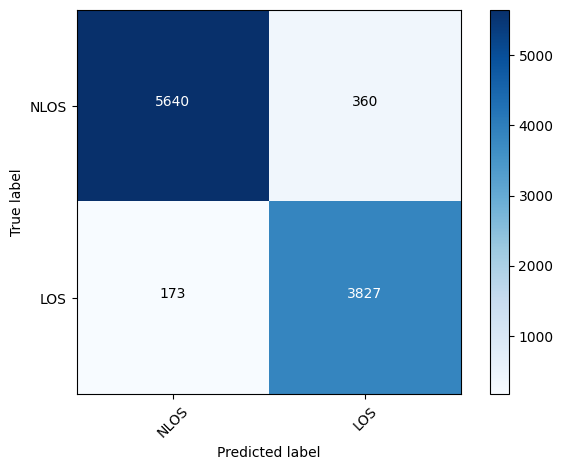

Confusion Matrix:
[[5640  360]
 [ 173 3827]]


In [18]:
y_true = []
y_pred = []
y_prob = []
print("Test dataset shape:", test_dataset.element_spec[0].shape, test_dataset.element_spec[1].shape)
for x_test, y_test in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))
y_prob = [p[0] for p in y_prob]
print(y_true)
print(y_pred)
print(y_prob)
print_metrics(y_true, y_pred, y_prob)
plot_confusion_matrix(y_true, y_pred, title="")


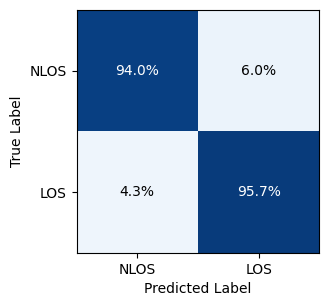

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Example confusion matrix for NLOS/LOS (replace with your actual results)
cm_nlos_los = np.array([
    [5640, 360],   # [True NLOS predicted as NLOS, True NLOS predicted as LOS]
    [173, 3827]    # [True LOS predicted as NLOS, True LOS predicted as LOS]
])
labels = ["NLOS", "LOS"]

def plot_cm_percent_binary(cm, labels, filename):
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100
    fig, ax = plt.subplots(figsize=(4, 3))
    im = ax.imshow(cm_percent, interpolation='nearest', cmap=plt.cm.Blues, vmin=0, vmax=100)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=0, ha='center')
    ax.set_yticklabels(labels)
    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            ax.text(j, i, f"{cm_percent[i, j]:.1f}%",
                    ha="center", va="center",
                    color="white" if cm_percent[i, j] > 50 else "black")
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout(pad=0.5)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

plot_cm_percent_binary(cm_nlos_los, labels, "confusion_matrix_mimo_nlos_los_percent.png")

CHANNEL CLASSIFICATION

dim: 32, h.shape[2]: 14
dim: 64, h.shape[2]: 7
dim: 128, h.shape[2]: 7


Model: "resnet18_custom"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (16, 192, 14, 2)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (16, 96, 7, 16)   │      1,568 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 96, 7, 16)   │         64 │ conv2d_30[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_26 (ReLU)     │ (16, 96, 7, 16)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (16, 48, 7, 16)   │          0 │ re_lu_26[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (16, 48, 7, 32)   │      4,608 │ max_pooling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_31[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_27 (ReLU)     │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (16, 48, 7, 32)   │      9,216 │ re_lu_27[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (16, 48, 7, 32)   │        512 │ max_pooling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_32[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_33[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_28 (ReLU)     │ (16, 48, 7, 32)   │          0 │ add_8[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (16, 48, 7, 32)   │      9,216 │ re_lu_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_34[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_29 (ReLU)     │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (16, 48, 7, 32)   │      9,216 │ re_lu_29[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (16, 48, 7, 32)   │        128 │ conv2d_35[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (16, 48, 7, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ re_lu_28[0][0]  

 Total params: 2,933,226 (11.19 MB)

 Trainable params: 2,928,394 (11.17 MB)

...

Model for epoch 25 converted to ONNX and saved at resnet_siso_models_channel/20250705-054529/model_epoch_25.onnx
Epoch 26/200
Epoch 26 Loss: 0.1571, Accuracy: 0.9403
Validation Loss: 0.9416, Accuracy: 0.7541


I0000 00:00:1751686187.272183 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751686187.272363 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751686187.273610 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751686188.145406 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751686188.468996 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751686188.469176 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751686188.470388 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Model for epoch 26 converted to ONNX and saved at resnet_siso_models_channel/20250705-054529/model_epoch_26.onnx
Epoch 27/200
Epoch 27 Loss: 0.1420, Accuracy: 0.9461
Validation Loss: 0.9757, Accuracy: 0.7528


I0000 00:00:1751686221.024931 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751686221.025109 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751686221.029411 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751686221.869344 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13447 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:18:00.0, compute capability: 7.0
I0000 00:00:1751686222.838743 3108426 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1751686222.838912 3108426 single_machine.cc:374] Starting new session
I0000 00:00:1751686222.840179 3108426 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Model for epoch 27 converted to ONNX and saved at resnet_siso_models_channel/20250705-054529/model_epoch_27.onnx
Early stopping triggered
Loading best model from resnet_siso_models_channel/20250705-054529/best_model.onnx
Test Loss: 0.6802, Test Accuracy: 0.7398


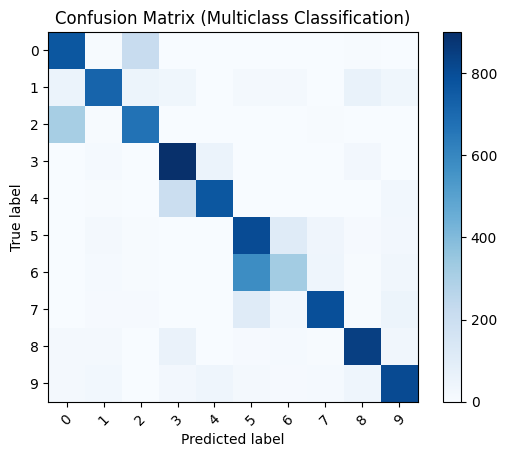

Confusion Matrix:
[[767   6 214   2   0   2   0   3   4   2]
 [ 55 720  48  35   2  21  21   3  61  34]
 [313   6 670   1   0   0   1   6   0   3]
 [  2  14   0 901  55   1   2   0  22   3]
 [  0   5   0 203 765   0   0   0   2  25]
 [  2  16   5   0   0 804 107  36   8  22]
 [  3  14   7   0   1 578 322  40   5  30]
 [  1   8   8   0   0 107  28 794   6  48]
 [ 16  20   2  57   3   9  11   5 847  30]
 [ 19  25   3  24  40  17   9  14  41 808]]


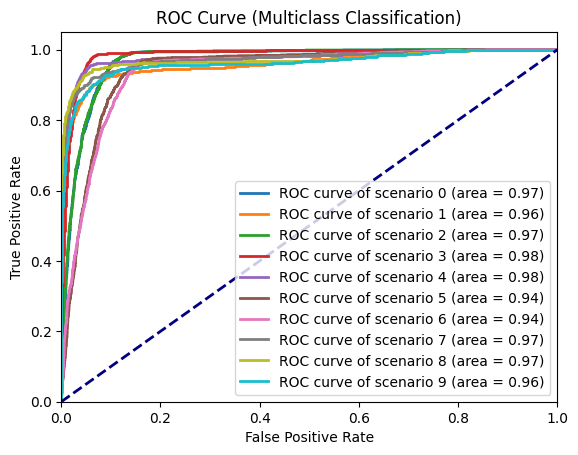

/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Accuracy: 0.7398
Precision: 0.7535
Recall: 0.7398
F1 Score: 0.7357
ROC AUC: 0.9643
Log Loss: 1.7550
Train Loss: 0.3000, Train Accuracy: 0.8689
Train Loss: 0.3000, Train Accuracy: 0.8689


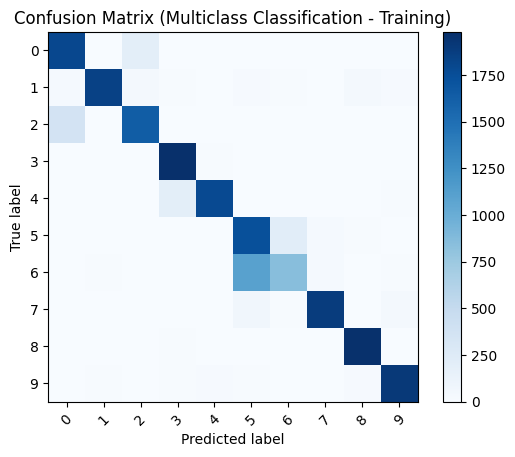

Confusion Matrix:
[[1796    5  195    3    0    0    0    0    0    1]
 [  29 1846   38    8    1   19    8    2   32   17]
 [ 357    6 1634    1    0    0    0    2    0    0]
 [   1    1    0 1980    9    0    2    0    6    1]
 [   0    1    0  199 1785    0    1    0    0   14]
 [   0    7    2    0    0 1733  214   29    8    7]
 [   0    9    2    0    0 1104  844   25    4   12]
 [   0    1    2    0    0   66   13 1881    4   33]
 [   2    4    0   15    0    2    0    0 1971    6]
 [   7   14    2   11   16   15    5    6   16 1908]]


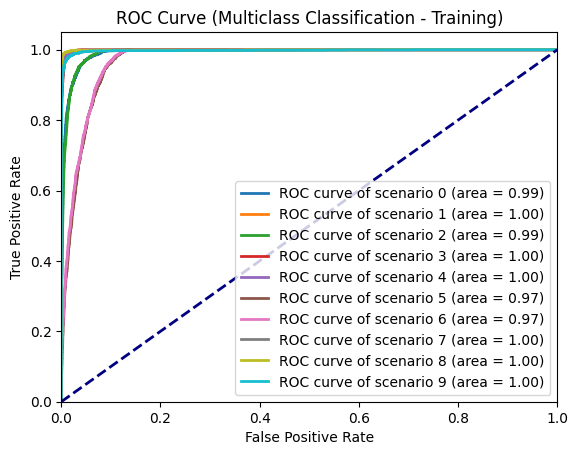

Accuracy: 0.8689
Precision: 0.8798
Recall: 0.8689
F1 Score: 0.8656
ROC AUC: 0.9917
Log Loss: 1.6451


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [20]:
n_downsamplings = 3
n_blocks = 0
num_rx_tx = 4  # Number of receive and transmit antennas
input_shape = (192, 14, 2)  # (4, 192, 14)
dim = 16
patience = 150
num_classes = np.unique(train_data_channel_labels).shape[0]
model = VGGNet(
    batch_size=batch_size,
    input_shape=input_shape,
    num_rx_tx=num_rx_tx,
    num_classes=num_classes,
    dim=dim,
    n_downsamplings=n_downsamplings,
    n_blocks=n_blocks,
    norm='instance_norm'
)
model = ResNet18(input_shape=(192, 14, 2), num_classes=10, batch_size=16)
model.summary()
# save model h5
model.save("model.h5")
# TensorBoard writer
writer = tf.summary.create_file_writer(channel_log_dir)

# Define the loss function
loss_fn = tf.keras.losses.BinaryCrossentropy() if num_classes == 2 else tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
# print the loss function
# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0003)

# Define metrics
train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
val_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# Training loop
epochs = 200 # Set the number of epochs
best_loss = float('inf')  # Track the best validation loss

train_dataset = train_dataset_siso_channel
# valid_dataset = valid_dataset_siso_channel
test_dataset = test_dataset_siso_channel
# train_dataset = train_dataset_mimo_channel
# # valid_dataset = valid_dataset_mimo_channel
# test_dataset = test_dataset_mimo_channel
@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def test_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    test_accuracy.update_state(y_batch, logits)
    return loss


# Training loop
for epoch in range(epochs):
    print(f"Epoch {epoch + 1}/{epochs}")
    epoch_loss = 0.0
    train_accuracy.reset_state()

    for x_batch, y_batch in train_dataset:
        loss = train_step(x_batch, y_batch)
        
        epoch_loss += loss.numpy()
    
    epoch_loss /= len(train_dataset)
    train_acc = train_accuracy.result().numpy()

    # Log training metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("training loss", epoch_loss, step=epoch)
        tf.summary.scalar("training accuracy", train_acc, step=epoch)

    print(f"Epoch {epoch + 1} Loss: {epoch_loss:.4f}, Accuracy: {train_acc:.4f}")

    # Validation loop
    test_loss = 0.0
    test_accuracy.reset_state()
    for x_test, y_test in test_dataset:
        loss = test_step(x_test, y_test)
        test_loss += loss.numpy()

    test_loss /= len(test_dataset)
    test_acc = test_accuracy.result().numpy()

    # Log validation metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("test loss", test_loss, step=epoch)
        tf.summary.scalar("test accuracy", test_acc, step=epoch)

    print(f"Validation Loss: {test_loss:.4f}, Accuracy: {test_acc:.4f}")

    # Save the ONNX model at each epoch
    onnx_model_path = os.path.join(channel_save_dir, f"model_epoch_{epoch + 1:02d}.onnx")
    spec = (tf.TensorSpec((None,) + input_shape, tf.float32),)
    onnx_model, _ = tf2onnx.convert.from_keras(model, input_signature=spec, opset=11)
    with open(onnx_model_path, "wb") as f:
        f.write(onnx_model.SerializeToString())
    print(f"Model for epoch {epoch + 1} converted to ONNX and saved at {onnx_model_path}")

    # Save the best model based on validation loss
    
    if test_loss < best_loss or epoch == 0:
        best_loss = test_loss
        best_onnx_model_path = os.path.join(channel_save_dir, "best_model.onnx")
        with open(best_onnx_model_path, "wb") as f:
            f.write(onnx_model.SerializeToString())
        print("Best model saved in ONNX format based on test loss")
        patience = 15
    else:
        patience -= 1
        if patience == 0:
            print("Early stopping triggered")
            break
        
# Load the best model
best_model_path = os.path.join(channel_save_dir, "best_model.onnx")
if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}")
    # Use ONNX Runtime to load the ONNX model
    ort_session = ort.InferenceSession(best_model_path)
else:
    raise FileNotFoundError(f"Best model not found at {best_model_path}")

# Evaluate the model
test_loss = 0.0
test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
test_accuracy.reset_state()

y_true = []
y_pred = []
y_prob = []

for x_test, y_test in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy() if num_classes > 2 else (test_logits > 0.5).astype(int))

    
test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()

print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]

# Visualize metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)
else:
    # Multiclass classification
    classes = list(range(num_classes))  # Replace with actual class names if available
    plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
    plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
    print_metrics_multiclass(y_true, y_pred, y_prob)
    
# Training dataset evaluation values
train_loss = 0.0
train_accuracy.reset_state()
y_true = []
y_pred = []
y_prob = []

for x_train, y_train in train_dataset:
    # Convert input to numpy for ONNX Runtime
    x_train_np = x_train.numpy()
    # Run inference using ONNX Runtime
    train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
    train_loss += loss_fn(y_train, train_logits).numpy()
    train_accuracy.update_state(y_train, train_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_train.numpy())
    y_prob.extend(tf.nn.softmax(train_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
    y_pred.extend(tf.argmax(train_logits, axis=1).numpy() if num_classes > 2 else (train_logits > 0.5).astype(int))
train_loss /= len(train_dataset)
train_acc = train_accuracy.result().numpy()
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]
# Visualize metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)

# Evaluate the model on the training dataset
train_loss = 0.0
train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
train_accuracy.reset_state()

y_train_true = []
y_train_pred = []
y_train_prob = []

for x_train, y_train in train_dataset:
    # Convert input to numpy for ONNX Runtime
    x_train_np = x_train.numpy()
    # Run inference using ONNX Runtime
    train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
    train_loss += loss_fn(y_train, train_logits).numpy()
    train_accuracy.update_state(y_train, train_logits)

    # Collect true labels, predicted labels, and probabilities
    y_train_true.extend(y_train.numpy())
    y_train_prob.extend(tf.nn.softmax(train_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
    y_train_pred.extend(tf.argmax(train_logits, axis=1).numpy() if num_classes > 2 else (train_logits > 0.5).astype(int))

train_loss /= len(train_dataset)
train_acc = train_accuracy.result().numpy()

print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")

# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_train_prob = [p[0] for p in y_train_prob]

# Visualize training metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_train_true, y_train_pred, title="Confusion Matrix (Binary Classification - Training)")
    plot_roc_curve(y_train_true, y_train_prob, title="ROC Curve (Binary Classification - Training)")
    print_metrics(y_train_true, y_train_pred, y_train_prob)
else:
    # Multiclass classification
    plot_confusion_matrix_multiclass(y_train_true, y_train_pred, classes, title="Confusion Matrix (Multiclass Classification - Training)")
    plot_roc_curve_multiclass(y_train_true, np.array(y_train_prob), classes, title="ROC Curve (Multiclass Classification - Training)")
    print_metrics_multiclass(y_train_true, y_train_pred, y_train_prob)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Updated confusion matrix
cm_siso_new = np.array([
    [767,   6, 214,   2,   0,   2,   0,   3,   4,   2],
    [ 55, 720,  48,  35,   2,  21,  21,   3,  61,  34],
    [313,   6, 670,   1,   0,   0,   1,   6,   0,   3],
    [  2,  14,   0, 901,  55,   1,   2,   0,  22,   3],
    [  0,   5,   0, 203, 765,   0,   0,   0,   2,  25],
    [  2,  16,   5,   0,   0, 804, 107,  36,   8,  22],
    [  3,  14,   7,   0,   1, 578, 322,  40,   5,  30],
    [  1,   8,   8,   0,   0, 107,  28, 794,   6,  48],
    [ 16,  20,   2,  57,   3,   9,  11,   5, 847,  30],
    [ 19,  25,   3,  24,  40,  17,   9,  14,  41, 808]
])

labels = [
    r"TDL $\mathsf{A}$", r"TDL $\mathsf{B}$", r"TDL $\mathsf{C}$", r"TDL $\mathsf{D}$", r"TDL $\mathsf{E}$",
    r"CDL $\mathsf{A}$", r"CDL $\mathsf{B}$", r"CDL $\mathsf{C}$", r"CDL $\mathsf{D}$", r"CDL $\mathsf{E}$"
]

def plot_cm_percent(cm, labels, filename):
    cm_percent = cm / 1000 * 100  # 1000 samples per class
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm_percent, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticklabels(labels)
    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            ax.text(j, i, f"{cm_percent[i, j]:.1f}%",
                    ha="center", va="center",
                    color="white" if cm_percent[i, j] > cm_percent.max() / 2 else "black")
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout(pad=0.5)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()
plot_cm_percent(cm_siso_new, labels, "confusion_matrix_siso_resnet_new_percent.png")

In [36]:
import onnxruntime as ort  # ONNX Runtime for inference
# train_dataset = train_dataset_mimo_channel
# valid_dataset = test_dataset_mimo_channel
# test_dataset = test_dataset_mimo_channel
train_dataset = train_dataset_siso_channel
valid_dataset = test_dataset_siso_channel
test_dataset = test_dataset_siso_channel
# Load the best model
best_model_path = os.path.join(nlos_los_save_dir, "best_model.onnx")
# /home/l2nguyen/long_nguyen_thesis/model_epoch_36.onnx, best model path here

# Define the loss function
# loss_fn = tf.keras.losses.BinaryCrossentropy() if num_classes == 2 else tf.keras.losses.SparseCategoricalCrossentropy()
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0003)
# optimizer = tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9)  # SGD with momentum

# Define metrics
# train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# val_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
train_accuracy = SparseCategoricalAccuracy()
val_accuracy = SparseCategoricalAccuracy()
test_accuracy = SparseCategoricalAccuracy()
n_downsamplings = 3
n_blocks = 0
num_rx_tx = 4  # Number of receive and transmit antennas
input_shape = (192, 14, 2)  # (4, 192, 14)
dim = 16
num_classes = np.unique(train_data_channel_labels).shape[0]

# model = VGGNet(
#     batch_size=batch_size,
#     input_shape=input_shape,
#     num_rx_tx=num_rx_tx,
#     num_classes=num_classes,
#     dim=dim,
#     n_downsamplings=n_downsamplings,
#     n_blocks=n_blocks,
#     norm='instance_norm'
# )



# model.summary()
# Optimize dataset loading
# Define training and validation steps with @tf.function for graph execution
@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def val_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    val_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def test_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    test_accuracy.update_state(y_batch, logits)
    return loss
best_model_path = "/home/l2nguyen/long_nguyen_thesis/resnet_siso_models_channel/20250704-042126/best_model.onnx"
if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}")
    # Use ONNX Runtime to load the ONNX model
    ort_session = ort.InferenceSession(best_model_path)
else:
    raise FileNotFoundError(f"Best model not found at {best_model_path}")

# Evaluate the model
test_loss = 0.0
# test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
test_accuracy = SparseCategoricalAccuracy()
test_accuracy.reset_state()

y_true = []
y_pred = []
y_prob = []
print("Test dataset shape:", test_dataset.element_spec[0].shape, test_dataset.element_spec[1].shape)
for x_test, y_test in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy() if num_classes > 2 else (test_logits > 0.5).astype(int))
test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
y_prob = [p[0] for p in y_prob]
# check how many classes in y_true

# print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
print(f"Test dataset 0db shape:", test_dataset_0db_mimo.element_spec[0].shape, test_dataset_0db_mimo.element_spec[1].shape)
# for x_test, y_test in test_dataset_0db_mimo:
# for x_test, y_test in test_dataset_0db_mimo_channel:
for x_test, y_test in test_dataset_0db_siso_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(f"Metrics for 0db")
# y_prob = [p[0] for p in y_prob]
# print_metrics(y_true, y_pred, y_prob)
print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
# for x_test, y_test in test_dataset_5db_mimo_channel:
for x_test, y_test in test_dataset_5db_siso_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 5db")
print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
# for x_test, y_test in test_dataset_10db_mimo_channel:
for x_test, y_test in test_dataset_10db_siso_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 10db")
# y_prob = [p[0] for p in y_prob]
# print_metrics(y_true, y_pred, y_prob)
print_metrics_multiclass(y_true, y_pred, y_prob)
y_true = []
y_pred = []
y_prob = []
# for x_test, y_test in test_dataset_15db_mimo_channel:
for x_test, y_test in test_dataset_15db_siso_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

# y_prob = [p[0] for p in y_prob]
print(f"Metrics for 15db")
print_metrics_multiclass(y_true, y_pred, y_prob)


print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(num_classes)
# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_prob = [p[0] for p in y_prob]

# # Visualize metrics
# if num_classes == 2:
#     # Binary classification
#     # plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
#     # plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
#     print_metrics(y_true, y_pred, y_prob)
# else:
#     # Multiclass classification
#     # classes = list(range(num_classes))  # Replace with actual class names if available
#     # plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
#     # plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
#     print_metrics_multiclass(y_true, y_pred, y_prob, classes)
    
# # training dataset evaluation metrics result
# train_loss = 0.0
# train_accuracy.reset_state()
# y_true_train = []
# y_pred_train = []
# y_prob_train = []
# for x_train, y_train in train_dataset:
#     # Convert input to numpy for ONNX Runtime
#     x_train_np = x_train.numpy()
#     # Run inference using ONNX Runtime
#     train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
#     train_loss += loss_fn(y_train, train_logits).numpy()
#     train_accuracy.update_state(y_train, train_logits)

#     # Collect true labels, predicted labels, and probabilities
#     y_true_train.extend(y_train.numpy())
#     y_prob_train.extend(tf.nn.softmax(train_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
#     y_pred_train.extend(tf.argmax(train_logits, axis=1).numpy()) # if num_classes > 2 else (train_logits > 0.5).astype(int))
# train_loss /= len(train_dataset)
# train_acc = train_accuracy.result().numpy()
# print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_prob_train = [p[0] for p in y_prob_train]
# # Visualize metrics
# if num_classes == 2:
#     # Binary classification
#     # plot_confusion_matrix(y_true_train, y_pred_train, title="Confusion Matrix (Binary Classification)")
#     # plot_roc_curve(y_true_train, y_prob_train, title="ROC Curve (Binary Classification)")
#     print_metrics(y_true_train, y_pred_train, y_prob_train)

# train_dataset = train_dataset_mimo_channel
# # valid_dataset = valid_dataset_mimo_channel
# test_dataset = test_dataset_mimo_channel

Loading best model from /home/l2nguyen/long_nguyen_thesis/resnet_siso_models_channel/20250704-042126/best_model.onnx
Test dataset shape: (None, 192, 14, 2) (None,)
Test Loss: 0.6934, Test Accuracy: 0.7159
Test dataset 0db shape: (None, 192, 14, 4) (None,)
Test Loss: 0.8448, Test Accuracy: 0.6895
Metrics for 0db
Accuracy: 0.6630
Precision: 0.6685
Recall: 0.6630
F1 Score: 0.6585
ROC AUC: 0.9501
Log Loss: 1.8349


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 5db
Accuracy: 0.7265
Precision: 0.7304
Recall: 0.7265
F1 Score: 0.7244
ROC AUC: 0.9643
Log Loss: 1.7750


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 10db
Accuracy: 0.7396
Precision: 0.7448
Recall: 0.7396
F1 Score: 0.7380
ROC AUC: 0.9669
Log Loss: 1.7617


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 15db
Accuracy: 0.7475
Precision: 0.7533
Recall: 0.7475
F1 Score: 0.7459
ROC AUC: 0.9700
Log Loss: 1.7530
Test Loss: 1178.5248, Test Accuracy: 0.6895
10


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [22]:
import onnxruntime as ort
import numpy as np
import os

# Set up test dataset (already batched)
# test_dataset = test_dataset_mimo_channel  # or test_dataset_siso_channel
test_dataset = test_dataset_siso_channel

# Path to the best ONNX model
best_model_path = os.path.join(channel_save_dir, "best_model.onnx")
if not os.path.exists(best_model_path):
    raise FileNotFoundError(f"Best model not found at {best_model_path}")
print(f"Loading best model from {best_model_path}")
ort_session = ort.InferenceSession(best_model_path)

# Define the loss function and metric
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
test_accuracy = tf.keras.metrics.SparseCategoricalAccuracy()
test_accuracy.reset_state()

# Evaluation loop
test_loss = 0.0
y_true = []
y_pred = []
y_prob = []

for x_test, y_test in test_dataset:
    x_test_np = x_test.numpy()
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy() if num_classes > 2 else (test_logits > 0.5).astype(int))

test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

# For binary classification, flatten probabilities
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]

# Print metrics (choose the right function for your task)
if num_classes == 2:
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)
else:
    # classes = list(range(num_classes))
    # plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
    # plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
    print_metrics_multiclass(y_true, y_pred, y_prob)
    
# for x_test, y_test in test_dataset_0db_mimo_channel:
for x_test, y_test in test_dataset_0db_siso_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # print(x_test_np)
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(f"Metrics for 0db")
# y_prob = [p[0] for p in y_prob]
# print(y_true)
# print(y_pred)
# print(y_prob)
# print_metrics(y_true, y_pred, y_prob)
print_metrics_multiclass(y_true, y_pred, y_prob)


Loading best model from resnet_siso_models_channel/20250704-042126/best_model.onnx
Test Loss: 0.6934, Test Accuracy: 0.7159
Accuracy: 0.7159
Precision: 0.7214
Recall: 0.7159
F1 Score: 0.7141
ROC AUC: 0.9628
Log Loss: 1.7844


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Test Loss: 0.8448, Test Accuracy: 0.6895
Metrics for 0db
Accuracy: 0.6895
Precision: 0.6948
Recall: 0.6895
F1 Score: 0.6864
ROC AUC: 0.9568
Log Loss: 1.8097


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [ ]:
y_true = []
y_pred = []
y_prob = []
# for x_test, y_test in test_dataset_5db_mimo_channel:
for x_test, y_test in test_dataset_5db_siso_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 5db")
print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
# for x_test, y_test in test_dataset_10db_mimo_channel:
for x_test, y_test in test_dataset_10db_siso_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 10db")
print_metrics_multiclass(y_true, y_pred, y_prob)

y_true = []
y_pred = []
y_prob = []
# for x_test, y_test in test_dataset_15db_mimo_channel:
for x_test, y_test in test_dataset_15db_siso_channel:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy()) # if num_classes > 2 else (test_logits > 0.5).astype(int))

print(f"Metrics for 15db")
print_metrics_multiclass(y_true, y_pred, y_prob)


print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
print(num_classes)


# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_prob = [p[0] for p in y_prob]

# # Visualize metrics
# if num_classes == 2:
#     # Binary classification
#     # plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
#     # plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
#     print_metrics(y_true, y_pred, y_prob)
# else:
#     # Multiclass classification
#     # classes = list(range(num_classes))  # Replace with actual class names if available
#     # plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
#     # plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
#     print_metrics_multiclass(y_true, y_pred, y_prob, classes)
    
# # training dataset evaluation metrics result
# train_loss = 0.0
# train_accuracy.reset_state()
# y_true_train = []
# y_pred_train = []
# y_prob_train = []
# for x_train, y_train in train_dataset:
#     # Convert input to numpy for ONNX Runtime
#     x_train_np = x_train.numpy()
#     # Run inference using ONNX Runtime
#     train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
#     train_loss += loss_fn(y_train, train_logits).numpy()
#     train_accuracy.update_state(y_train, train_logits)

#     # Collect true labels, predicted labels, and probabilities
#     y_true_train.extend(y_train.numpy())
#     y_prob_train.extend(tf.nn.softmax(train_logits).numpy()) # if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
#     y_pred_train.extend(tf.argmax(train_logits, axis=1).numpy()) # if num_classes > 2 else (train_logits > 0.5).astype(int))
# train_loss /= len(train_dataset)
# train_acc = train_accuracy.result().numpy()
# print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
# # Convert probabilities to a flat list for binary classification
# if num_classes == 2:
#     y_prob_train = [p[0] for p in y_prob_train]
# # Visualize metrics
# if num_classes == 2:
#     # Binary classification
#     # plot_confusion_matrix(y_true_train, y_pred_train, title="Confusion Matrix (Binary Classification)")
#     # plot_roc_curve(y_true_train, y_prob_train, title="ROC Curve (Binary Classification)")
#     print_metrics(y_true_train, y_pred_train, y_prob_train)

Metrics for 5db
Accuracy: 0.8032
Precision: 0.8063
Recall: 0.8032
F1 Score: 0.8031
ROC AUC: 0.9772
Log Loss: 1.7011


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 10db
Accuracy: 0.8189
Precision: 0.8217
Recall: 0.8189
F1 Score: 0.8192
ROC AUC: 0.9806
Log Loss: 1.6809


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Metrics for 15db
Accuracy: 0.8250
Precision: 0.8296
Recall: 0.8250
F1 Score: 0.8253
ROC AUC: 0.9814
Log Loss: 1.6750
Test Loss: 873.3558, Test Accuracy: 0.7618
10


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
